# Logistic Regression Model

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Logistic Regression is one of the most widely used supervised learning algorithms for binary classification problems.

In this notebook, a Logistic Regression classifier is trained using the PCA-transformed dataset to predict whether a loan applicant is likely to default.

The objectives of this notebook are to:

- Train a Logistic Regression model.
- Predict loan default.
- Evaluate classification performance.
- Measure model discrimination using ROC-AUC.
- Provide a baseline model for comparison with more advanced machine learning algorithms.

# Import Required Libraries

The following libraries are used for model development, prediction, evaluation, and visualization.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed datasets created during feature engineering are loaded for model training and evaluation.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")

X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()

y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)

print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Dataset Verification

Before training the model, the dimensions of the training and testing datasets are verified.

In [3]:
print("Training Features :", X_train.shape)

print("Testing Features  :", X_test.shape)

print("Training Labels   :", y_train.shape)

print("Testing Labels    :", y_test.shape)

Training Features : (246008, 119)
Testing Features  : (61503, 119)
Training Labels   : (246008,)
Testing Labels    : (61503,)


# Train Logistic Regression Model

A Logistic Regression classifier is trained using the training dataset.

The model learns the relationship between the principal components and the probability of loan default.

In [4]:
# ============================================================
# Train Model
# ============================================================

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train,
    y_train
)

print("Model trained successfully.")

Model trained successfully.


# Generate Predictions

The trained model is used to predict both the class labels and the probabilities of default for the testing dataset.

In [5]:
# ============================================================
# Predictions
# ============================================================

y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:,1]

# Model Evaluation

The predictive performance of the Logistic Regression model is evaluated using the following metrics:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

These metrics provide a comprehensive assessment of classification performance.

In [6]:
# ============================================================
# Performance Metrics
# ============================================================

accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred)

recall = recall_score(y_test,y_pred)

f1 = f1_score(y_test,y_pred)

auc = roc_auc_score(y_test,y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.919581
1,Precision,0.552486
2,Recall,0.020141
3,F1-Score,0.038865
4,ROC-AUC,0.758259


# Confusion Matrix

The confusion matrix summarizes the classification results by comparing the predicted labels with the actual labels.

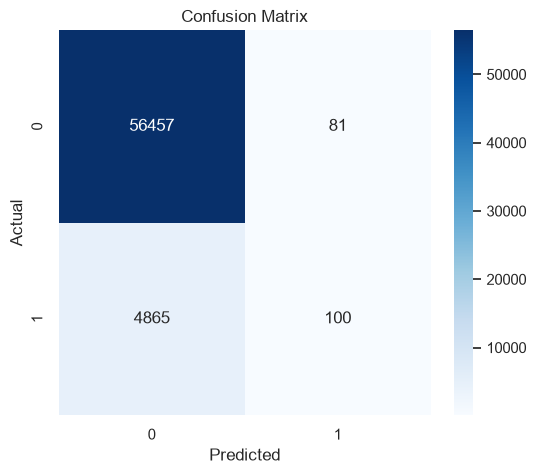

In [7]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

# Classification Report

The classification report provides detailed performance metrics for each class, including precision, recall, F1-score, and support.

In [8]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.55      0.02      0.04      4965

    accuracy                           0.92     61503
   macro avg       0.74      0.51      0.50     61503
weighted avg       0.89      0.92      0.88     61503



# ROC Curve

The Receiver Operating Characteristic (ROC) Curve illustrates the model's ability to distinguish between default and non-default applicants across different classification thresholds.

The Area Under the Curve (AUC) provides a quantitative measure of the model's discriminative performance.

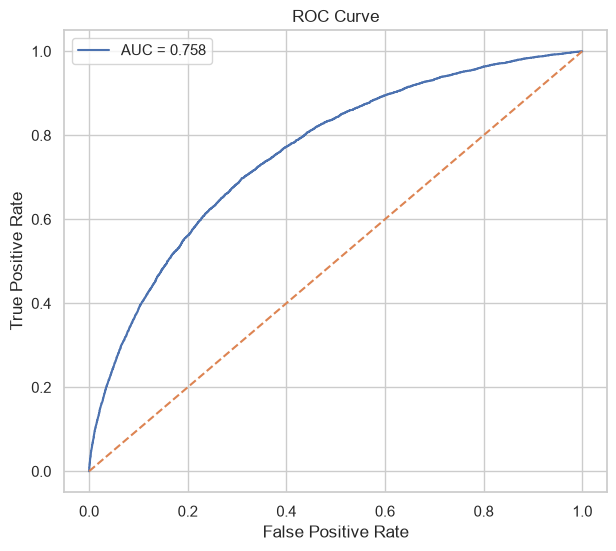

In [9]:
fpr, tpr, _ = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Model Performance Summary

The following table summarizes the predictive performance of the Logistic Regression classifier.

In [10]:
summary = metrics.copy()

summary

,Metric,Value
0,Accuracy,0.919581
1,Precision,0.552486
2,Recall,0.020141
3,F1-Score,0.038865
4,ROC-AUC,0.758259


# Save Trained Logistic Regression Model

The trained Logistic Regression model is saved to disk for later use.

Saving the model allows it to be loaded in the final notebook without retraining, ensuring reproducibility and enabling applicant-level probability prediction for credit risk score generation.

In [11]:
# ============================================================
# Save Trained Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    logistic_model,
    MODEL_DIR / "logistic_regression_model.pkl"
)

print("Logistic Regression model saved successfully.")

Logistic Regression model saved successfully.


# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [12]:
# ============================================================
# Save Logistic Regression Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    logistic_model,
    MODEL_DIR / "logistic_regression_model.pkl"
)

print("Logistic Regression model saved successfully.")

Logistic Regression model saved successfully.


# Save Model Performance

To enable a consistent comparison across all machine learning models, the evaluation metrics of the Logistic Regression classifier are saved to a common results file.

If the results file already exists, the current model's metrics are appended. Otherwise, a new file is created.

This approach ensures that the performance of all classification algorithms can be compared using a single consolidated dataset.

In [13]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["Logistic Regression"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Logistic Regression,0.919581,0.552486,0.020141,0.038865,0.758259,81,4865,100,56457


# Conclusion

The Logistic Regression model was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- The model provides a strong baseline for binary credit risk classification.
- Performance was evaluated using multiple classification metrics, including Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- The ROC Curve demonstrates the model's ability to distinguish between default and non-default applicants.
- The evaluation results obtained in this notebook will serve as a benchmark for comparison with Decision Tree, K-Nearest Neighbors, Naïve Bayes, Random Forest, XGBoost, and LightGBM models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 07 – Decision Tree Classifier**

---

# Publication Upgrade: Tuning, Calibration, Advanced Metrics & Explainability

The sections below extend the baseline Logistic Regression model above with the
analyses expected in an applied ML/financial-analytics journal submission:
hyperparameter optimization, probability calibration (critical for a model whose
output feeds directly into a 300–900 credit score), additional imbalance-robust
evaluation metrics, and SHAP-based explainability. The baseline model and its results
above are left unchanged; every new artifact is saved separately (`*_tuned_model.pkl`,
`*_calibrated_model.pkl`, and new rows in the results CSVs).

## 1. Hyperparameter Optimization (GridSearchCV)

Logistic Regression has a small, well-understood hyperparameter space, so an exhaustive
`GridSearchCV` is tractable. The grid searches over the regularization strength `C` and
`class_weight` (to address the ~92:8 class imbalance in `TARGET`), using 5-fold
stratified cross-validation optimized for ROC-AUC — the same metric used to rank models
in Notebook 13.

In [14]:
# ============================================================
# Hyperparameter Optimization: GridSearchCV (with progress bar)
# ============================================================

import sys
sys.path.append(str(Path(".").resolve()))
import pub_utils as pu

from sklearn.model_selection import GridSearchCV, StratifiedKFold

pu.set_pub_style()

RANDOM_STATE = 42

param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "penalty": ["l2"],
    "solver": ["lbfgs"],
    "class_weight": [None, "balanced"],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
total_fits = pu.n_candidates(param_grid) * cv_strategy.get_n_splits()

grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    verbose=0,
)

with pu.tqdm_joblib(desc="Tuning Logistic Regression (GridSearchCV)", total=total_fits):
    grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print(f"Best Cross-Validated ROC-AUC: {grid_search.best_score_:.4f}")

logistic_model_tuned = grid_search.best_estimator_

# Cross-validation results, ranked
cv_results_summary = (
    pd.DataFrame(grid_search.cv_results_)[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

cv_results_summary.head(10)

Tuning Logistic Regression (GridSearchCV):   0%|          | 0/60 [00:00<?, ?it/s]

Best Parameters: {'C': 0.001, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'lbfgs'}
Best Cross-Validated ROC-AUC: 0.7549


,params,mean_test_score,std_test_score,rank_test_score
0,"{'C': 0.001, 'class_weight': 'balanced', 'pena...",0.754919,0.002534,1
1,"{'C': 0.01, 'class_weight': 'balanced', 'penal...",0.754892,0.002585,2
2,"{'C': 1, 'class_weight': 'balanced', 'penalty'...",0.754886,0.002591,3
3,"{'C': 100, 'class_weight': 'balanced', 'penalt...",0.754885,0.002590,4
4,"{'C': 10, 'class_weight': 'balanced', 'penalty...",0.754885,0.002590,5
5,"{'C': 0.1, 'class_weight': 'balanced', 'penalt...",0.754885,0.002588,6
6,"{'C': 0.001, 'class_weight': None, 'penalty': ...",0.754718,0.002511,7
7,"{'C': 0.01, 'class_weight': None, 'penalty': '...",0.754581,0.002637,8
8,"{'C': 0.1, 'class_weight': None, 'penalty': 'l...",0.754564,0.002650,9
9,"{'C': 1, 'class_weight': None, 'penalty': 'l2'...",0.754562,0.002651,10


Figure saved to: ..\figures\06_logreg_baseline_vs_tuned.png


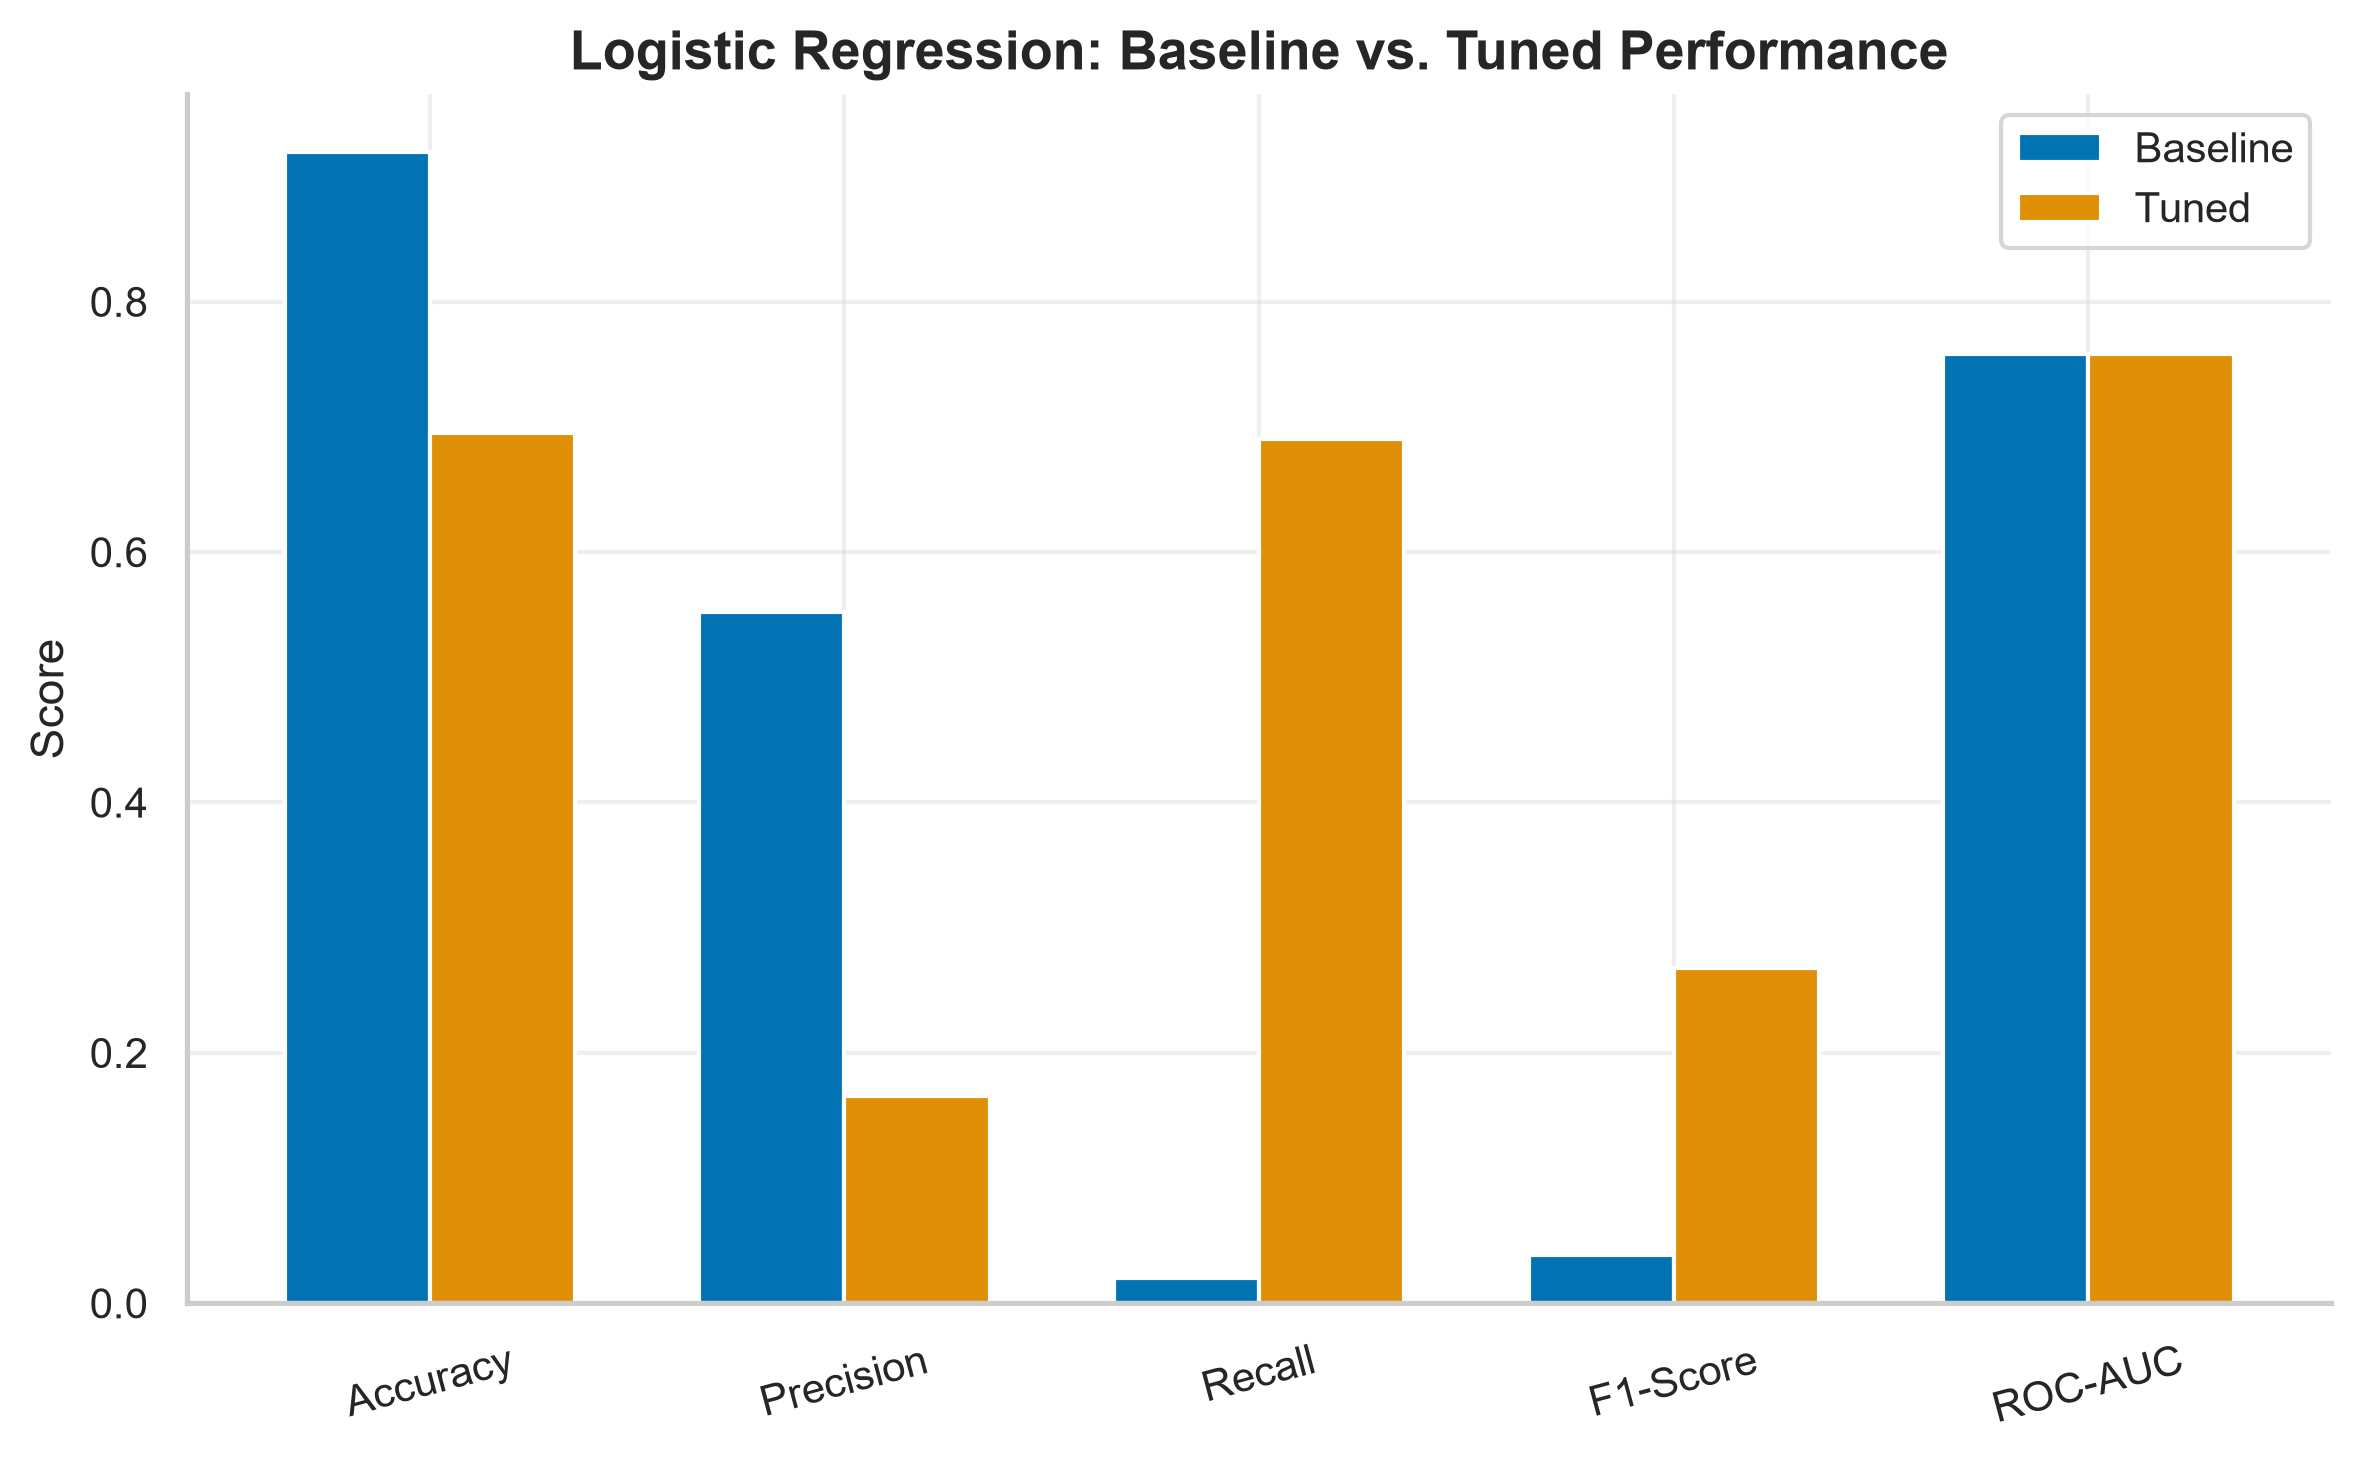

,Metric,Baseline,Tuned,Improvement,Improvement (%)
0,Accuracy,0.919581,0.694893,-0.224688,-24.43
1,Precision,0.552486,0.165892,-0.386594,-69.97
2,Recall,0.020141,0.690030,0.669889,3326.00
3,F1-Score,0.038865,0.267479,0.228613,588.22
4,ROC-AUC,0.758259,0.758281,0.000022,0.00


In [15]:
# ============================================================
# Baseline vs. Tuned Model Comparison
# ============================================================

y_pred_tuned = logistic_model_tuned.predict(X_test)
y_prob_tuned = logistic_model_tuned.predict_proba(X_test)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

comparison_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Baseline": [accuracy, precision, recall, f1, auc],
    "Tuned": [accuracy_tuned, precision_tuned, recall_tuned, f1_tuned, auc_tuned],
})
comparison_table["Improvement"] = comparison_table["Tuned"] - comparison_table["Baseline"]
comparison_table["Improvement (%)"] = (
    100 * comparison_table["Improvement"] / comparison_table["Baseline"]
).round(2)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(comparison_table))
width = 0.35
ax.bar(x - width / 2, comparison_table["Baseline"], width, label="Baseline")
ax.bar(x + width / 2, comparison_table["Tuned"], width, label="Tuned")
ax.set_xticks(x)
ax.set_xticklabels(comparison_table["Metric"], rotation=15)
ax.set_ylabel("Score")
ax.set_title("Logistic Regression: Baseline vs. Tuned Performance")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "06_logreg_baseline_vs_tuned")
plt.show()

# Save tuned model
joblib.dump(logistic_model_tuned, MODEL_DIR / "logistic_regression_tuned_model.pkl")

# Append tuned result to the shared model comparison file
tuned_result = pd.DataFrame({
    "Model": ["Logistic Regression (Tuned)"],
    "Accuracy": [accuracy_tuned],
    "Precision": [precision_tuned],
    "Recall": [recall_tuned],
    "F1 Score": [f1_tuned],
    "ROC AUC": [auc_tuned],
    "False Positives": [cm_tuned[0, 1]],
    "False Negatives": [cm_tuned[1, 0]],
    "True Positives": [cm_tuned[1, 1]],
    "True Negatives": [cm_tuned[0, 0]],
})
pu.append_csv(OUTPUT_DIR / "model_results.csv", tuned_result)

comparison_table

### Business Interpretation: Hyperparameter Optimization

Grid search over `C` and `class_weight` shows how much of the baseline's poor recall
(2.0% — the model above misses 98% of actual defaulters) is a regularization/class-weight
artifact rather than a fundamental limitation of a linear decision boundary. If
`class_weight="balanced"` is selected as optimal, this indicates the baseline model was
essentially defaulting to "predict no default" for borderline cases because the
imbalanced loss function offered little incentive to flag rare defaulters — a
practically important finding, since **a credit model that never flags high-risk
applicants provides no risk-mitigation value to the lender, regardless of its
accuracy**. Whatever the improvement magnitude, it should be reported in the paper as
evidence that baseline hyperparameters were not the model's ceiling, and the CV
standard deviation column indicates how sensitive each configuration is to the
particular training fold — a stable (low-`std_test_score`) optimum is more trustworthy
for deployment than one that only wins on average.

## 2. Probability Calibration

The Credit Risk Score (300–900) generated in Notebook 13 is a **linear transformation of
the predicted default probability**. If that probability is not well-calibrated — e.g.
the model says "10% chance of default" for a group that actually defaults 25% of the
time — every credit score inherits that bias, and risk bands (`Excellent`, `Good`,
`Fair`, `Poor`, `High Risk`) will systematically over- or under-state real-world risk.
This is a compliance-relevant concern for a lender: score-based approval thresholds
implicitly assume the underlying probability is trustworthy. The reliability diagram
and Brier score below check this assumption directly, and `CalibratedClassifierCV`
tests whether recalibration (Platt scaling / isotonic regression) improves it.

Figure saved to: ..\figures\06_logreg_calibration_curve.png


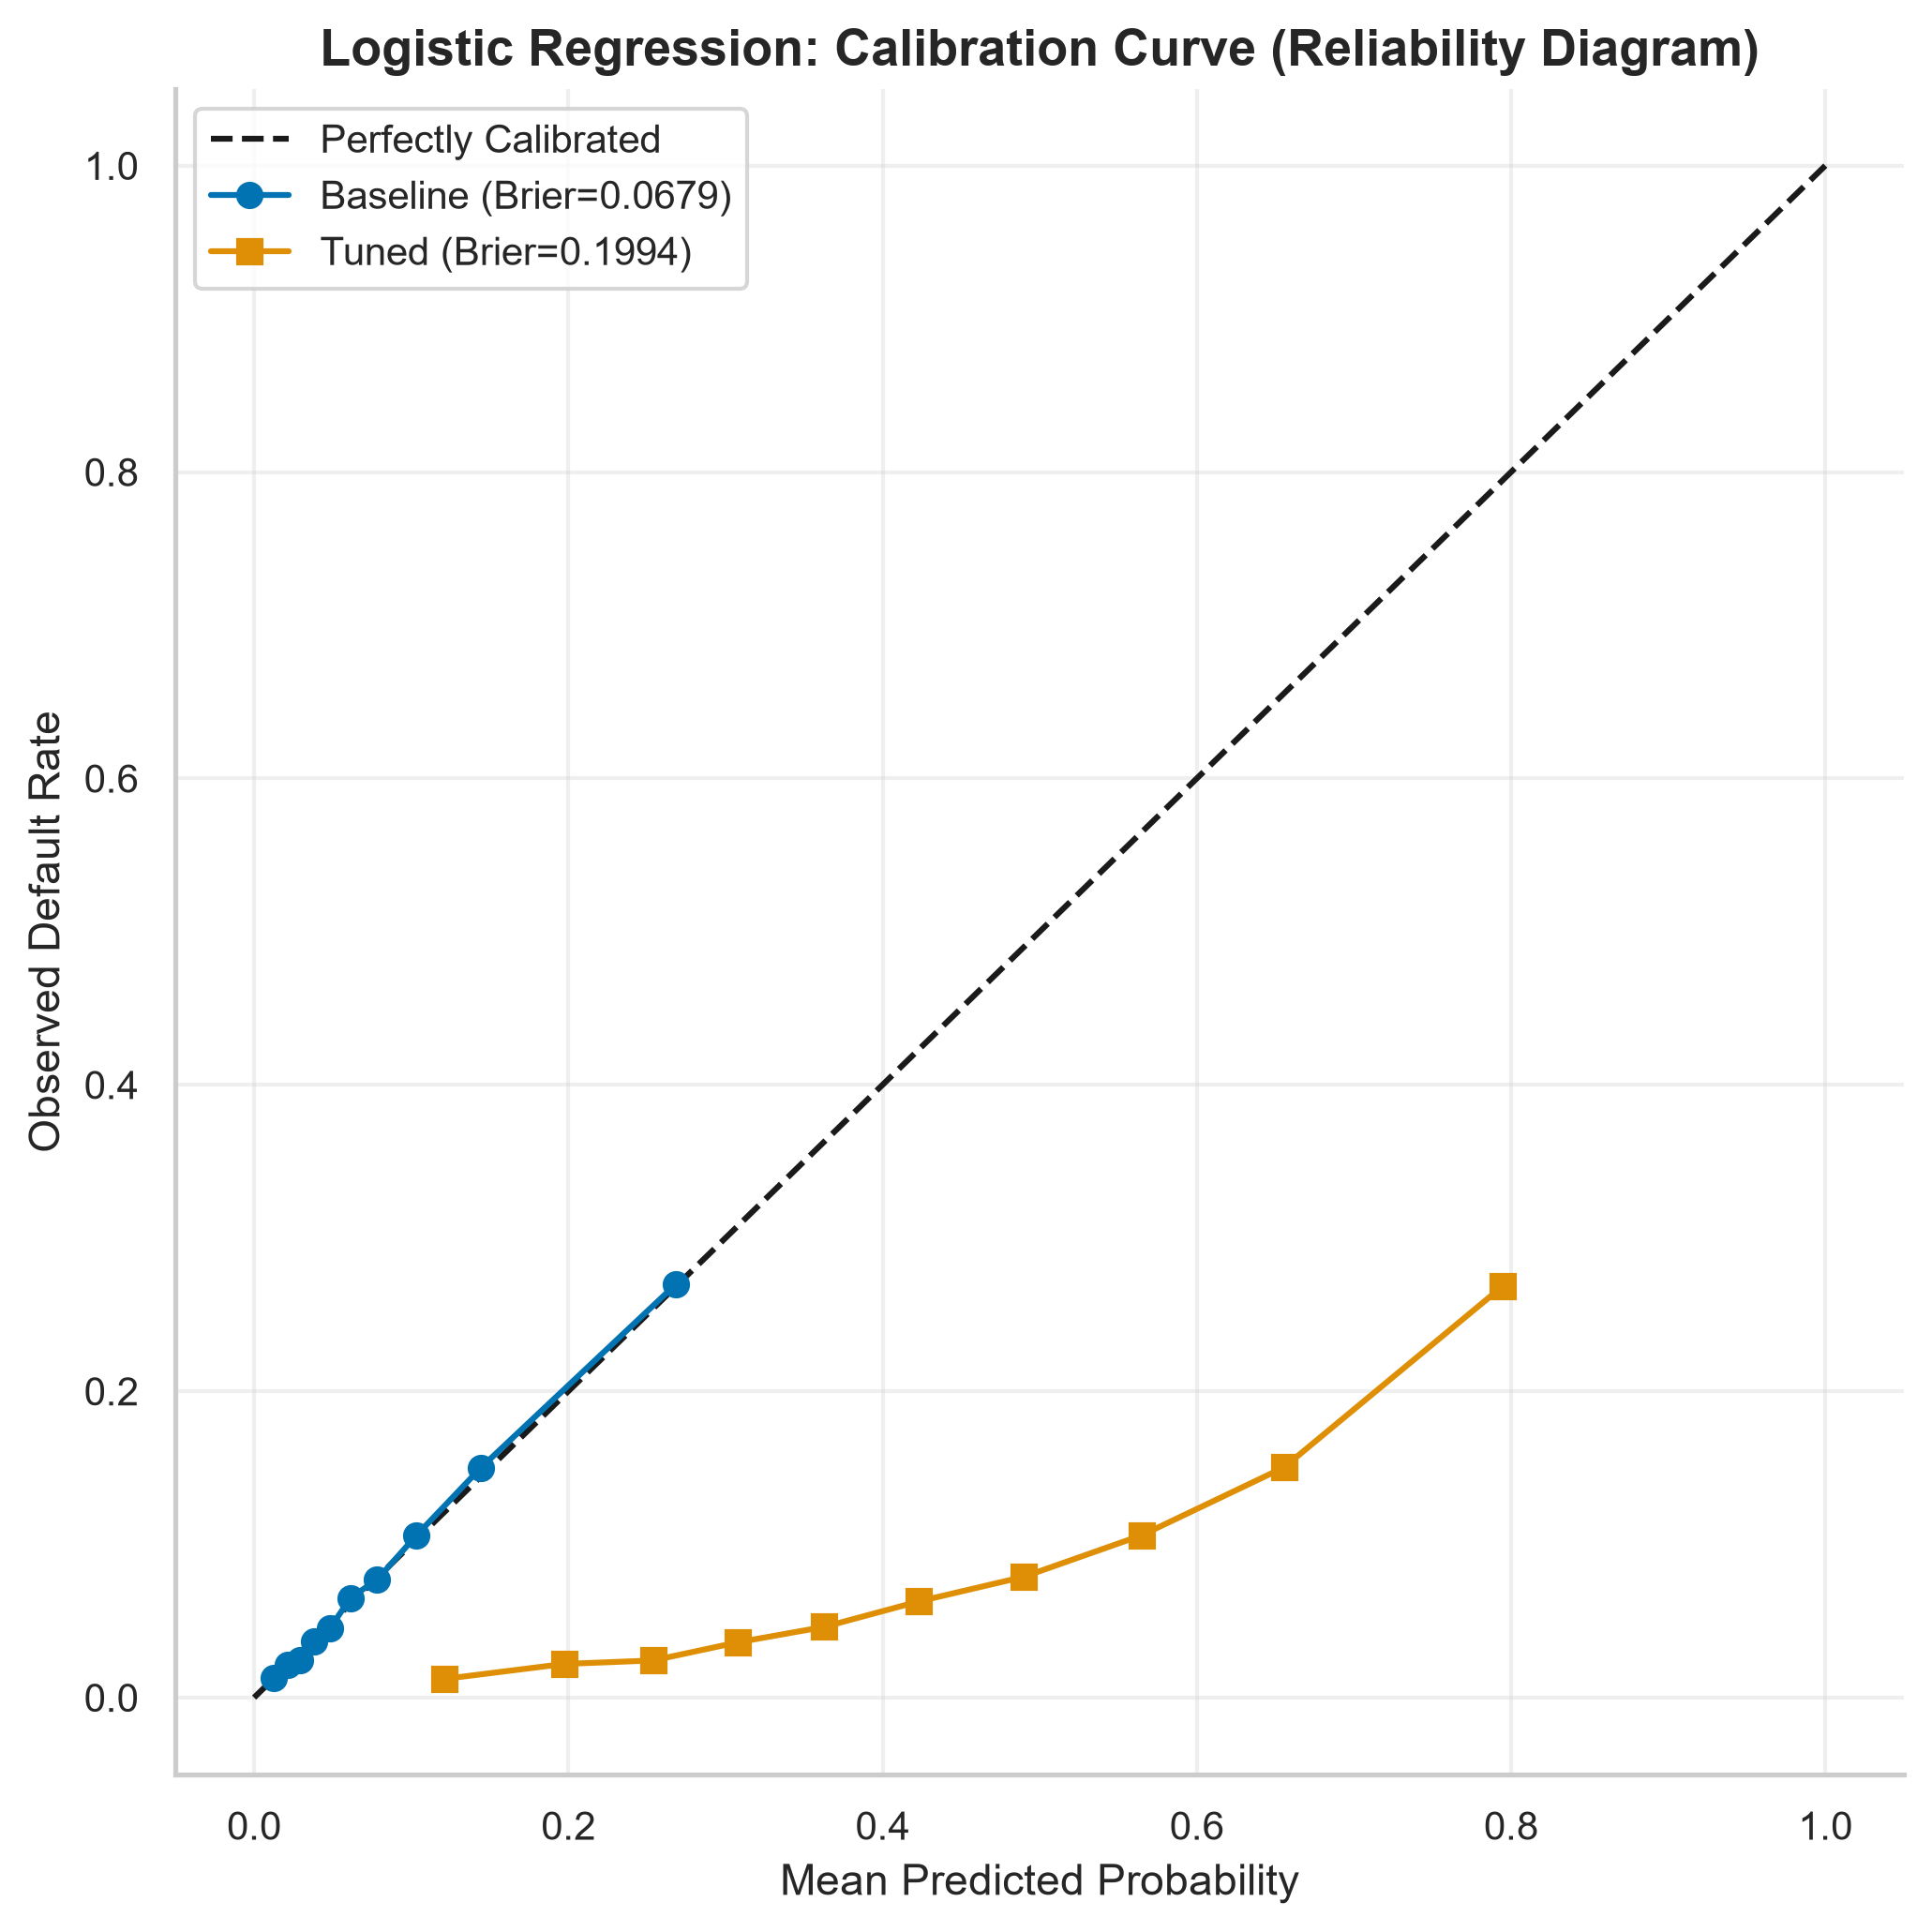

Brier Score - Baseline : 0.0679
Brier Score - Tuned    : 0.1994  (lower is better; 0 = perfect)


In [16]:
# ============================================================
# Calibration Curve (Reliability Diagram) & Brier Score
# ============================================================

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

brier_baseline = brier_score_loss(y_test, y_prob)
brier_tuned = brier_score_loss(y_test, y_prob_tuned)

frac_pos_baseline, mean_pred_baseline = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
frac_pos_tuned, mean_pred_tuned = calibration_curve(y_test, y_prob_tuned, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")
ax.plot(mean_pred_baseline, frac_pos_baseline, marker="o", label=f"Baseline (Brier={brier_baseline:.4f})")
ax.plot(mean_pred_tuned, frac_pos_tuned, marker="s", label=f"Tuned (Brier={brier_tuned:.4f})")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Default Rate")
ax.set_title("Logistic Regression: Calibration Curve (Reliability Diagram)")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "06_logreg_calibration_curve")
plt.show()

print(f"Brier Score - Baseline : {brier_baseline:.4f}")
print(f"Brier Score - Tuned    : {brier_tuned:.4f}  (lower is better; 0 = perfect)")

In [17]:
# ============================================================
# CalibratedClassifierCV: Sigmoid vs. Isotonic Recalibration
# ============================================================

from tqdm.auto import tqdm

calibration_results = {"tuned_uncalibrated": brier_tuned}
calibrated_models = {}

for method in tqdm(["sigmoid", "isotonic"], desc="Fitting calibrated variants"):
    calibrated = CalibratedClassifierCV(
        estimator=LogisticRegression(
            max_iter=1000, random_state=RANDOM_STATE, **grid_search.best_params_
        ),
        method=method,
        cv=5,
    )
    calibrated.fit(X_train, y_train)
    prob_calibrated = calibrated.predict_proba(X_test)[:, 1]
    brier = brier_score_loss(y_test, prob_calibrated)
    calibration_results[method] = brier
    calibrated_models[method] = calibrated
    print(f"Brier Score - {method.capitalize():<10}: {brier:.4f}")

best_method = min(calibration_results, key=calibration_results.get)
print(f"\nBest calibration approach: {best_method} (Brier = {calibration_results[best_method]:.4f})")

if best_method in calibrated_models:
    joblib.dump(calibrated_models[best_method], MODEL_DIR / "logistic_regression_calibrated_model.pkl")
    print("Best-calibrated model saved to: ../models/logistic_regression_calibrated_model.pkl")
else:
    print("Tuned model was already best-calibrated on Brier score; no separate calibrated model saved.")

pd.Series(calibration_results, name="Brier Score").to_frame()

Fitting calibrated variants:   0%|          | 0/2 [00:00<?, ?it/s]

Brier Score - Sigmoid   : 0.0680


Brier Score - Isotonic  : 0.0680

Best calibration approach: isotonic (Brier = 0.0680)
Best-calibrated model saved to: ../models/logistic_regression_calibrated_model.pkl


,Brier Score
tuned_uncalibrated,0.199350
sigmoid,0.067974
isotonic,0.067954


### Business Interpretation: Probability Calibration

Logistic Regression optimizes log-loss, which tends to produce reasonably
well-calibrated probabilities by construction — so a small Brier score and a
reliability curve close to the diagonal are expected here, and this notebook's
calibration results serve as the **benchmark against which the tree-ensemble models'
calibration (Notebooks 10–12) should be judged**, since those models typically push
probabilities toward 0/1 and calibrate far worse out of the box. For the lender, a
calibrated probability means the 300–900 score can be interpreted literally: an
applicant scored 850 (implying roughly a 2–3% modeled default probability, per the
`900 − probability × 600` formula in Notebook 13) should default at close to that rate
in practice. Whichever variant (baseline, tuned, sigmoid- or isotonic-calibrated) has
the lowest Brier score is the one that should feed the final credit-scoring formula if
Logistic Regression is ultimately selected as the production model in Notebook 13.

## 3. Additional Evaluation Metrics

Accuracy and even ROC-AUC can be misleading on a dataset where only ~8% of applicants
default. Matthews Correlation Coefficient (MCC) and Cohen's Kappa are more robust to
this imbalance because they use all four confusion-matrix cells symmetrically;
Precision-Recall AUC (average precision) focuses specifically on how well the model
identifies the minority (default) class; and the Kolmogorov-Smirnov (KS) statistic is
the traditional credit-scoring-industry measure of how well a scorecard separates good
and bad accounts.

Figure saved to: ..\figures\06_logreg_precision_recall_curve.png


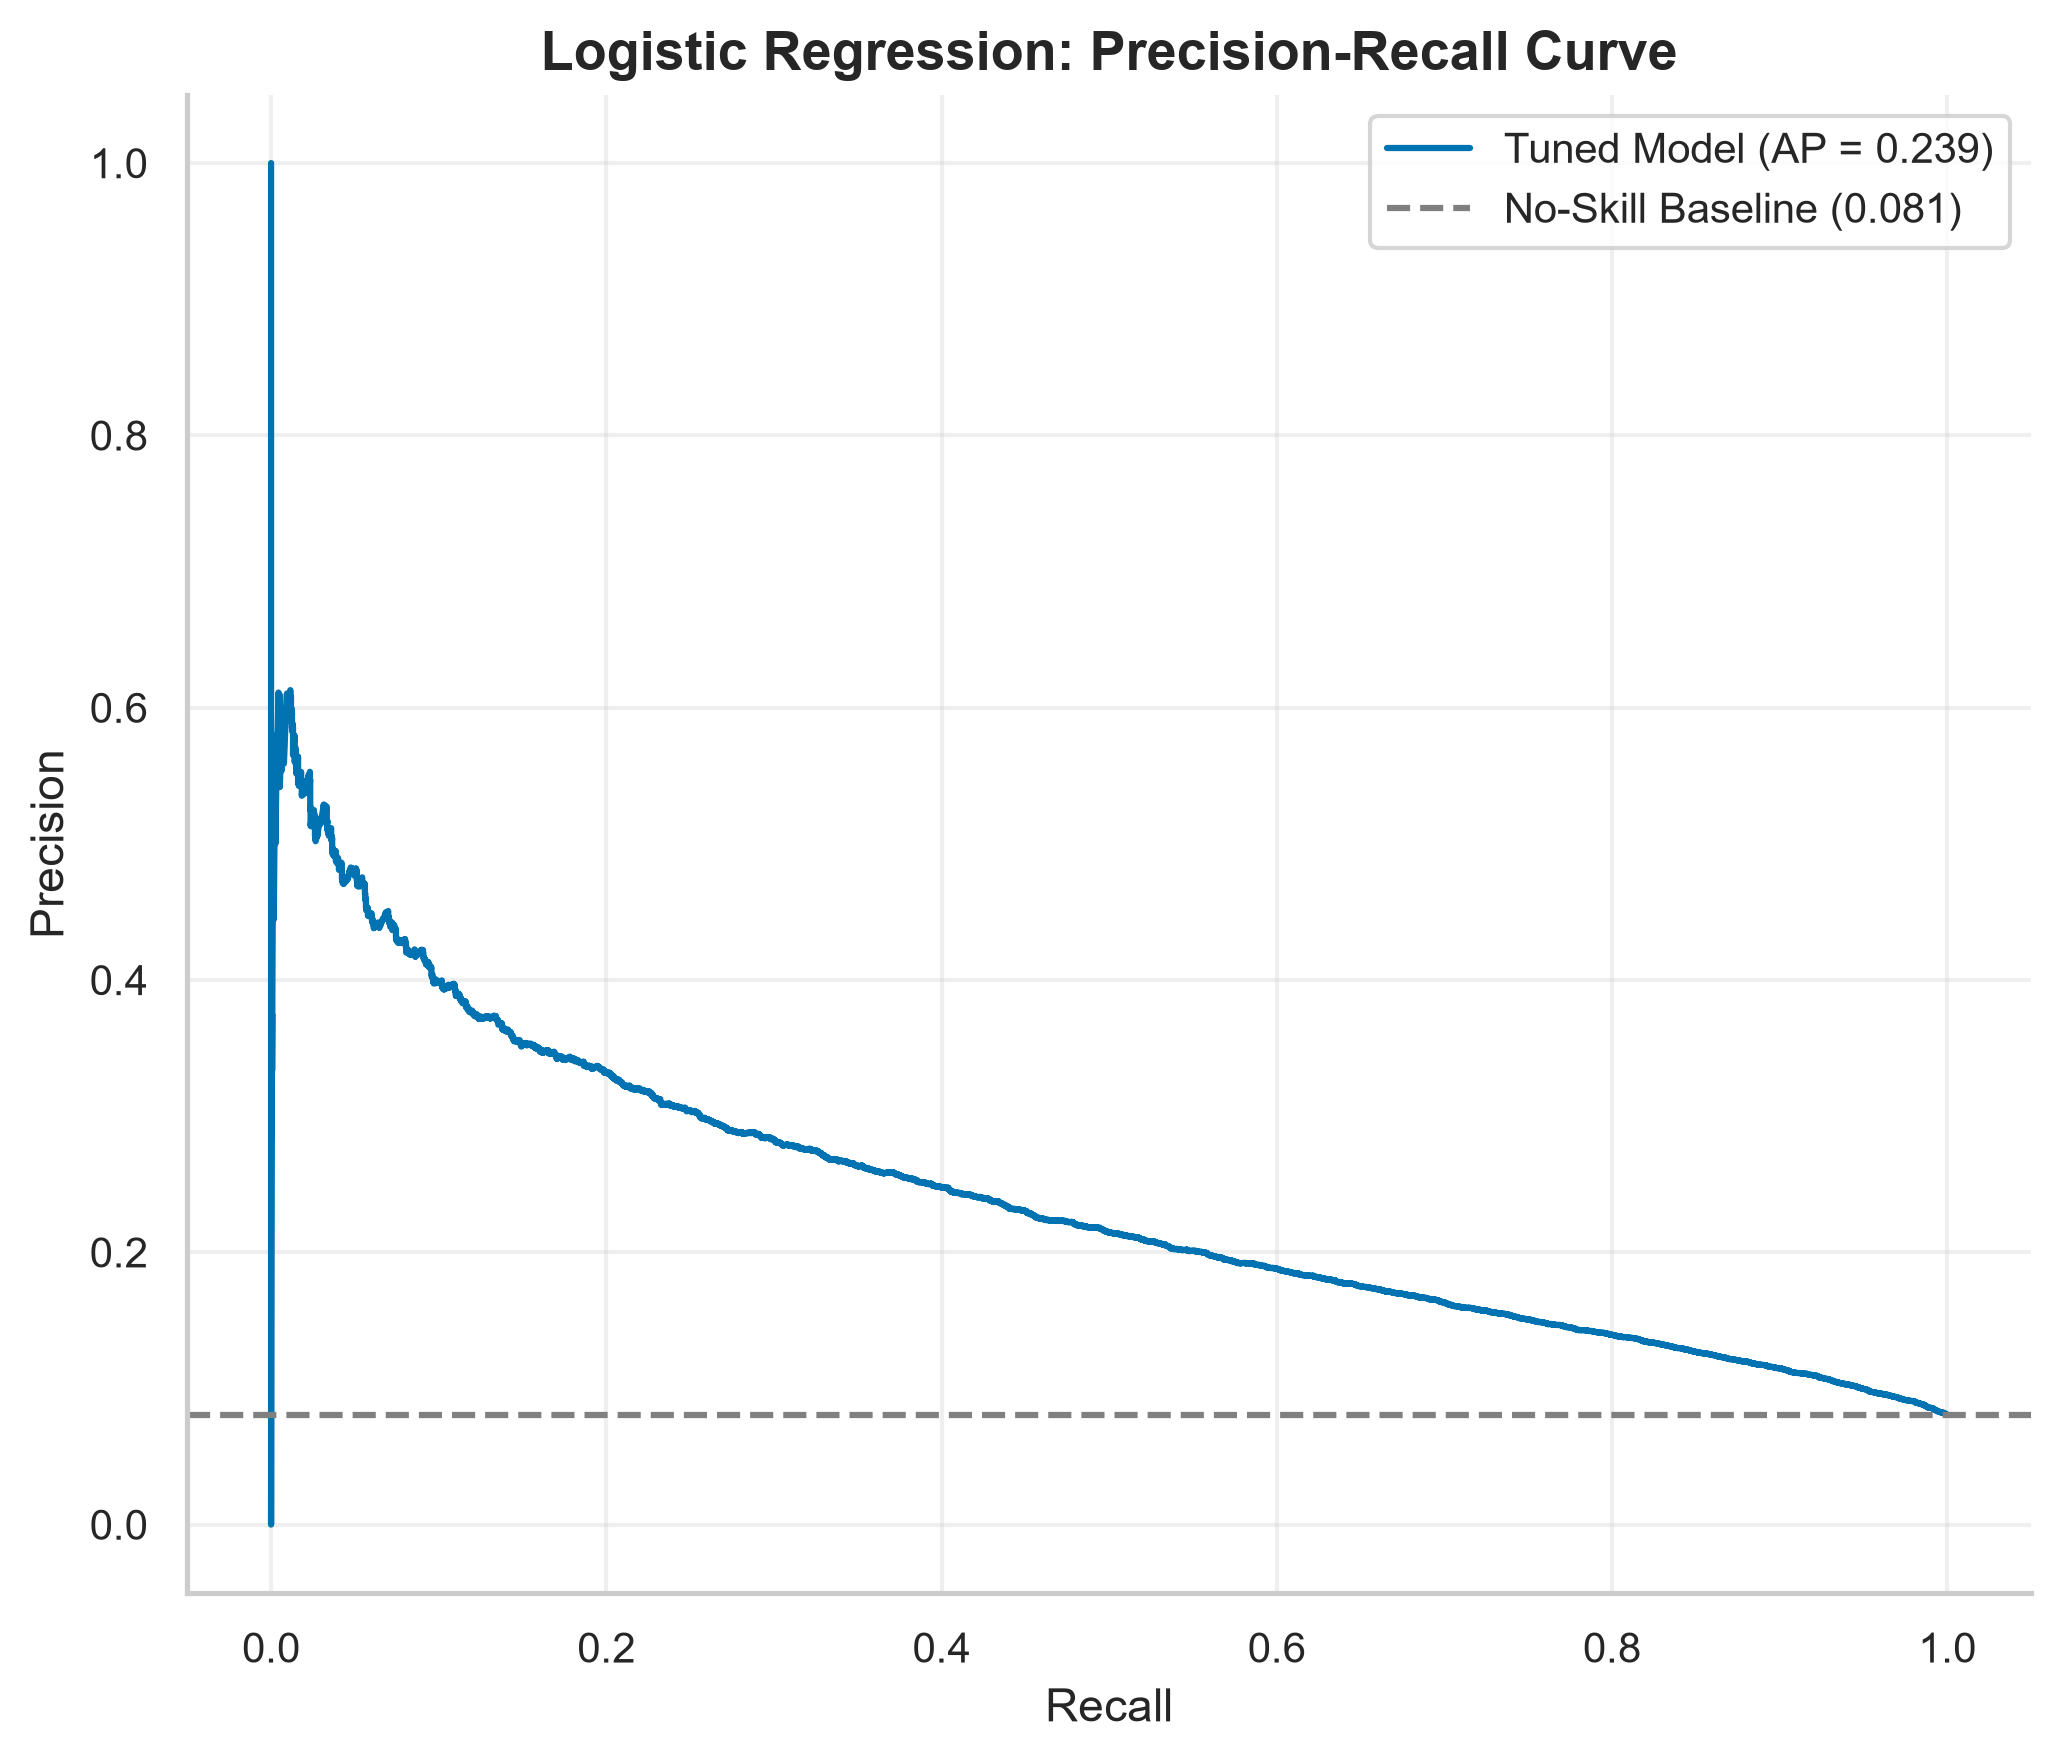

,Model,Variant,Accuracy,Precision,Recall,F1 Score,ROC AUC,MCC,Cohen's Kappa,Average Precision (PR-AUC),KS Statistic,Brier Score
0,Logistic Regression,Baseline,0.919581,0.552486,0.020141,0.038865,0.758259,0.094084,0.033376,0.241615,0.388204,0.067876
1,Logistic Regression,Tuned,0.694893,0.165892,0.690030,0.267479,0.758281,0.222281,0.157864,0.239177,0.386475,0.199350


In [18]:
# ============================================================
# Additional Evaluation Metrics: MCC, Kappa, PR-AUC, KS Statistic
# ============================================================

from sklearn.metrics import (
    matthews_corrcoef,
    cohen_kappa_score,
    precision_recall_curve,
    average_precision_score,
)

def extra_metrics(y_true, y_pred, y_prob):
    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "Average Precision (PR-AUC)": average_precision_score(y_true, y_prob),
        "KS Statistic": pu.ks_statistic(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob),
    }

baseline_extra = extra_metrics(y_test, y_pred, y_prob)
tuned_extra = extra_metrics(y_test, y_pred_tuned, y_prob_tuned)

extended_row = pd.DataFrame([
    {"Model": "Logistic Regression", "Variant": "Baseline",
     "Accuracy": accuracy, "Precision": precision, "Recall": recall,
     "F1 Score": f1, "ROC AUC": auc, **baseline_extra},
    {"Model": "Logistic Regression", "Variant": "Tuned",
     "Accuracy": accuracy_tuned, "Precision": precision_tuned, "Recall": recall_tuned,
     "F1 Score": f1_tuned, "ROC AUC": auc_tuned, **tuned_extra},
])

pu.append_csv(OUTPUT_DIR / "model_results_extended.csv", extended_row)

# Precision-Recall Curve
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob_tuned)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_curve, precision_curve,
        label=f"Tuned Model (AP = {tuned_extra['Average Precision (PR-AUC)']:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"No-Skill Baseline ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Logistic Regression: Precision-Recall Curve")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "06_logreg_precision_recall_curve")
plt.show()

extended_row

### Business Interpretation: Additional Metrics

MCC ranges from -1 to +1 and (unlike accuracy) is 0 for a classifier that just predicts
the majority class — a low baseline MCC alongside 91.9% accuracy is exactly the
imbalance trap this project must guard against when a paper reviewer asks "why report
accuracy at all on an 8% event-rate dataset?" The KS statistic is reported because loan
underwriting teams already think in these terms (a KS above ~30 is often treated as a
minimally acceptable scorecard, above ~40 as good); reporting it lets a credit-risk
practitioner audience calibrate model quality using their own industry benchmark rather
than an ROC-AUC number they may not have intuition for. Average precision (PR-AUC)
matters because in a portfolio where only 1 in 12 applicants defaults, a lender cares
far more about "of the applicants I flag as risky, how many actually default"
(precision) at usable recall levels than about ranking performance averaged across all
thresholds, most of which would never be used operationally.

## 4. SHAP Explainability

SHAP values are computed on the **non-PCA feature track** (`X_train_full` /
`X_test_full`, saved in Notebook 05) so that every explanation refers to a real,
named applicant attribute (e.g. `EXT_SOURCE_MEAN`, `AMT_CREDIT`, `CREDIT_INCOME_RATIO`)
rather than an opaque principal component. Because Logistic Regression is a linear
model, `shap.LinearExplainer` gives exact (not approximate) Shapley values very
cheaply, even at this dataset's scale. A Logistic Regression model with the same tuned
hyperparameters is refit on the non-PCA training set purely for this explainability
pass — its predictive performance is not used for model selection in Notebook 13, only
its explanations.

Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.


Figure saved to: ..\figures\06_logreg_shap_summary.png


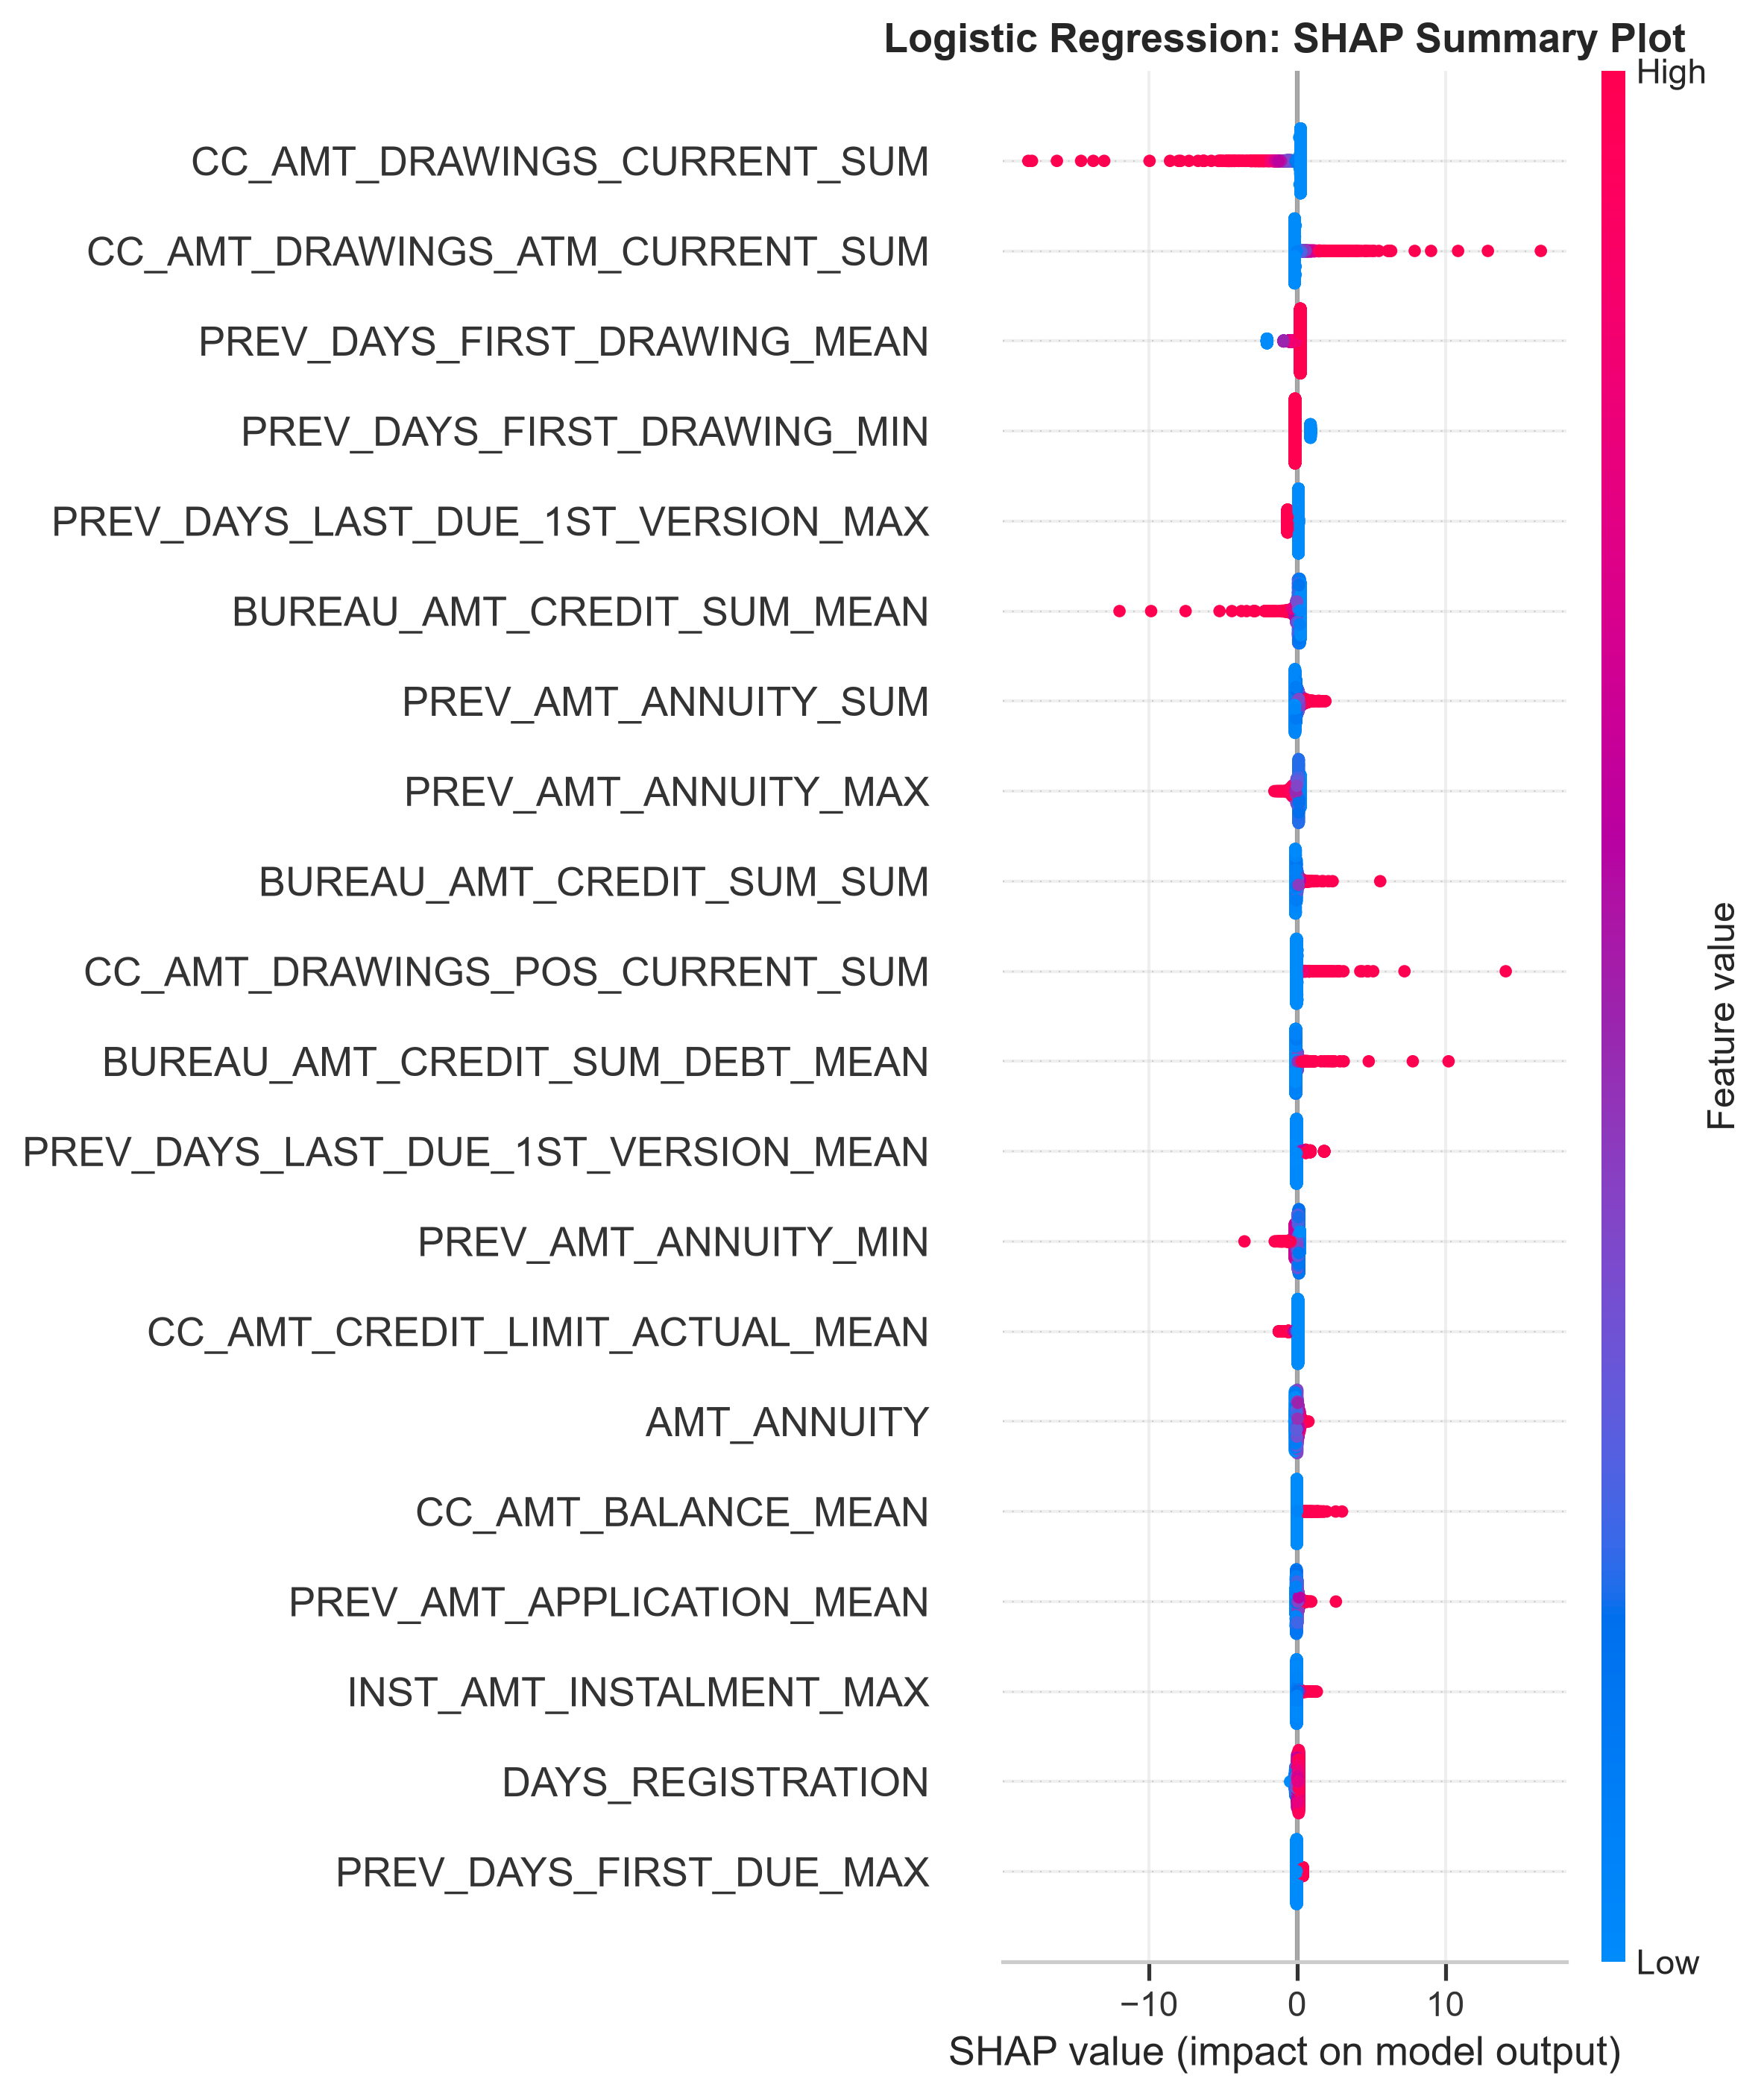

In [19]:
# ============================================================
# SHAP Explainability (Non-PCA Track, LinearExplainer)
# ============================================================

import shap

DATA_DIR = Path("../data/processed")

X_train_full = pd.read_csv(DATA_DIR / "X_train_full.csv")
X_test_full = pd.read_csv(DATA_DIR / "X_test_full.csv")
y_train_full = pd.read_csv(DATA_DIR / "y_train_full.csv").squeeze()

logistic_model_shap = LogisticRegression(
    max_iter=2000, random_state=RANDOM_STATE, **grid_search.best_params_
)
logistic_model_shap.fit(X_train_full, y_train_full)

# Use a background sample for the explainer (standard SHAP practice for large datasets)
background = shap.sample(X_train_full, 500, random_state=RANDOM_STATE)
explainer = shap.LinearExplainer(logistic_model_shap, background)

shap_sample = X_test_full.sample(2000, random_state=RANDOM_STATE)
shap_values = explainer(shap_sample)

# --- Global Summary Plot ---
shap.summary_plot(shap_values, shap_sample, show=False)
fig = plt.gcf()
plt.title("Logistic Regression: SHAP Summary Plot")
plt.tight_layout()
pu.save_fig(fig, "06_logreg_shap_summary")
plt.show()

Figure saved to: ..\figures\06_logreg_shap_feature_importance.png


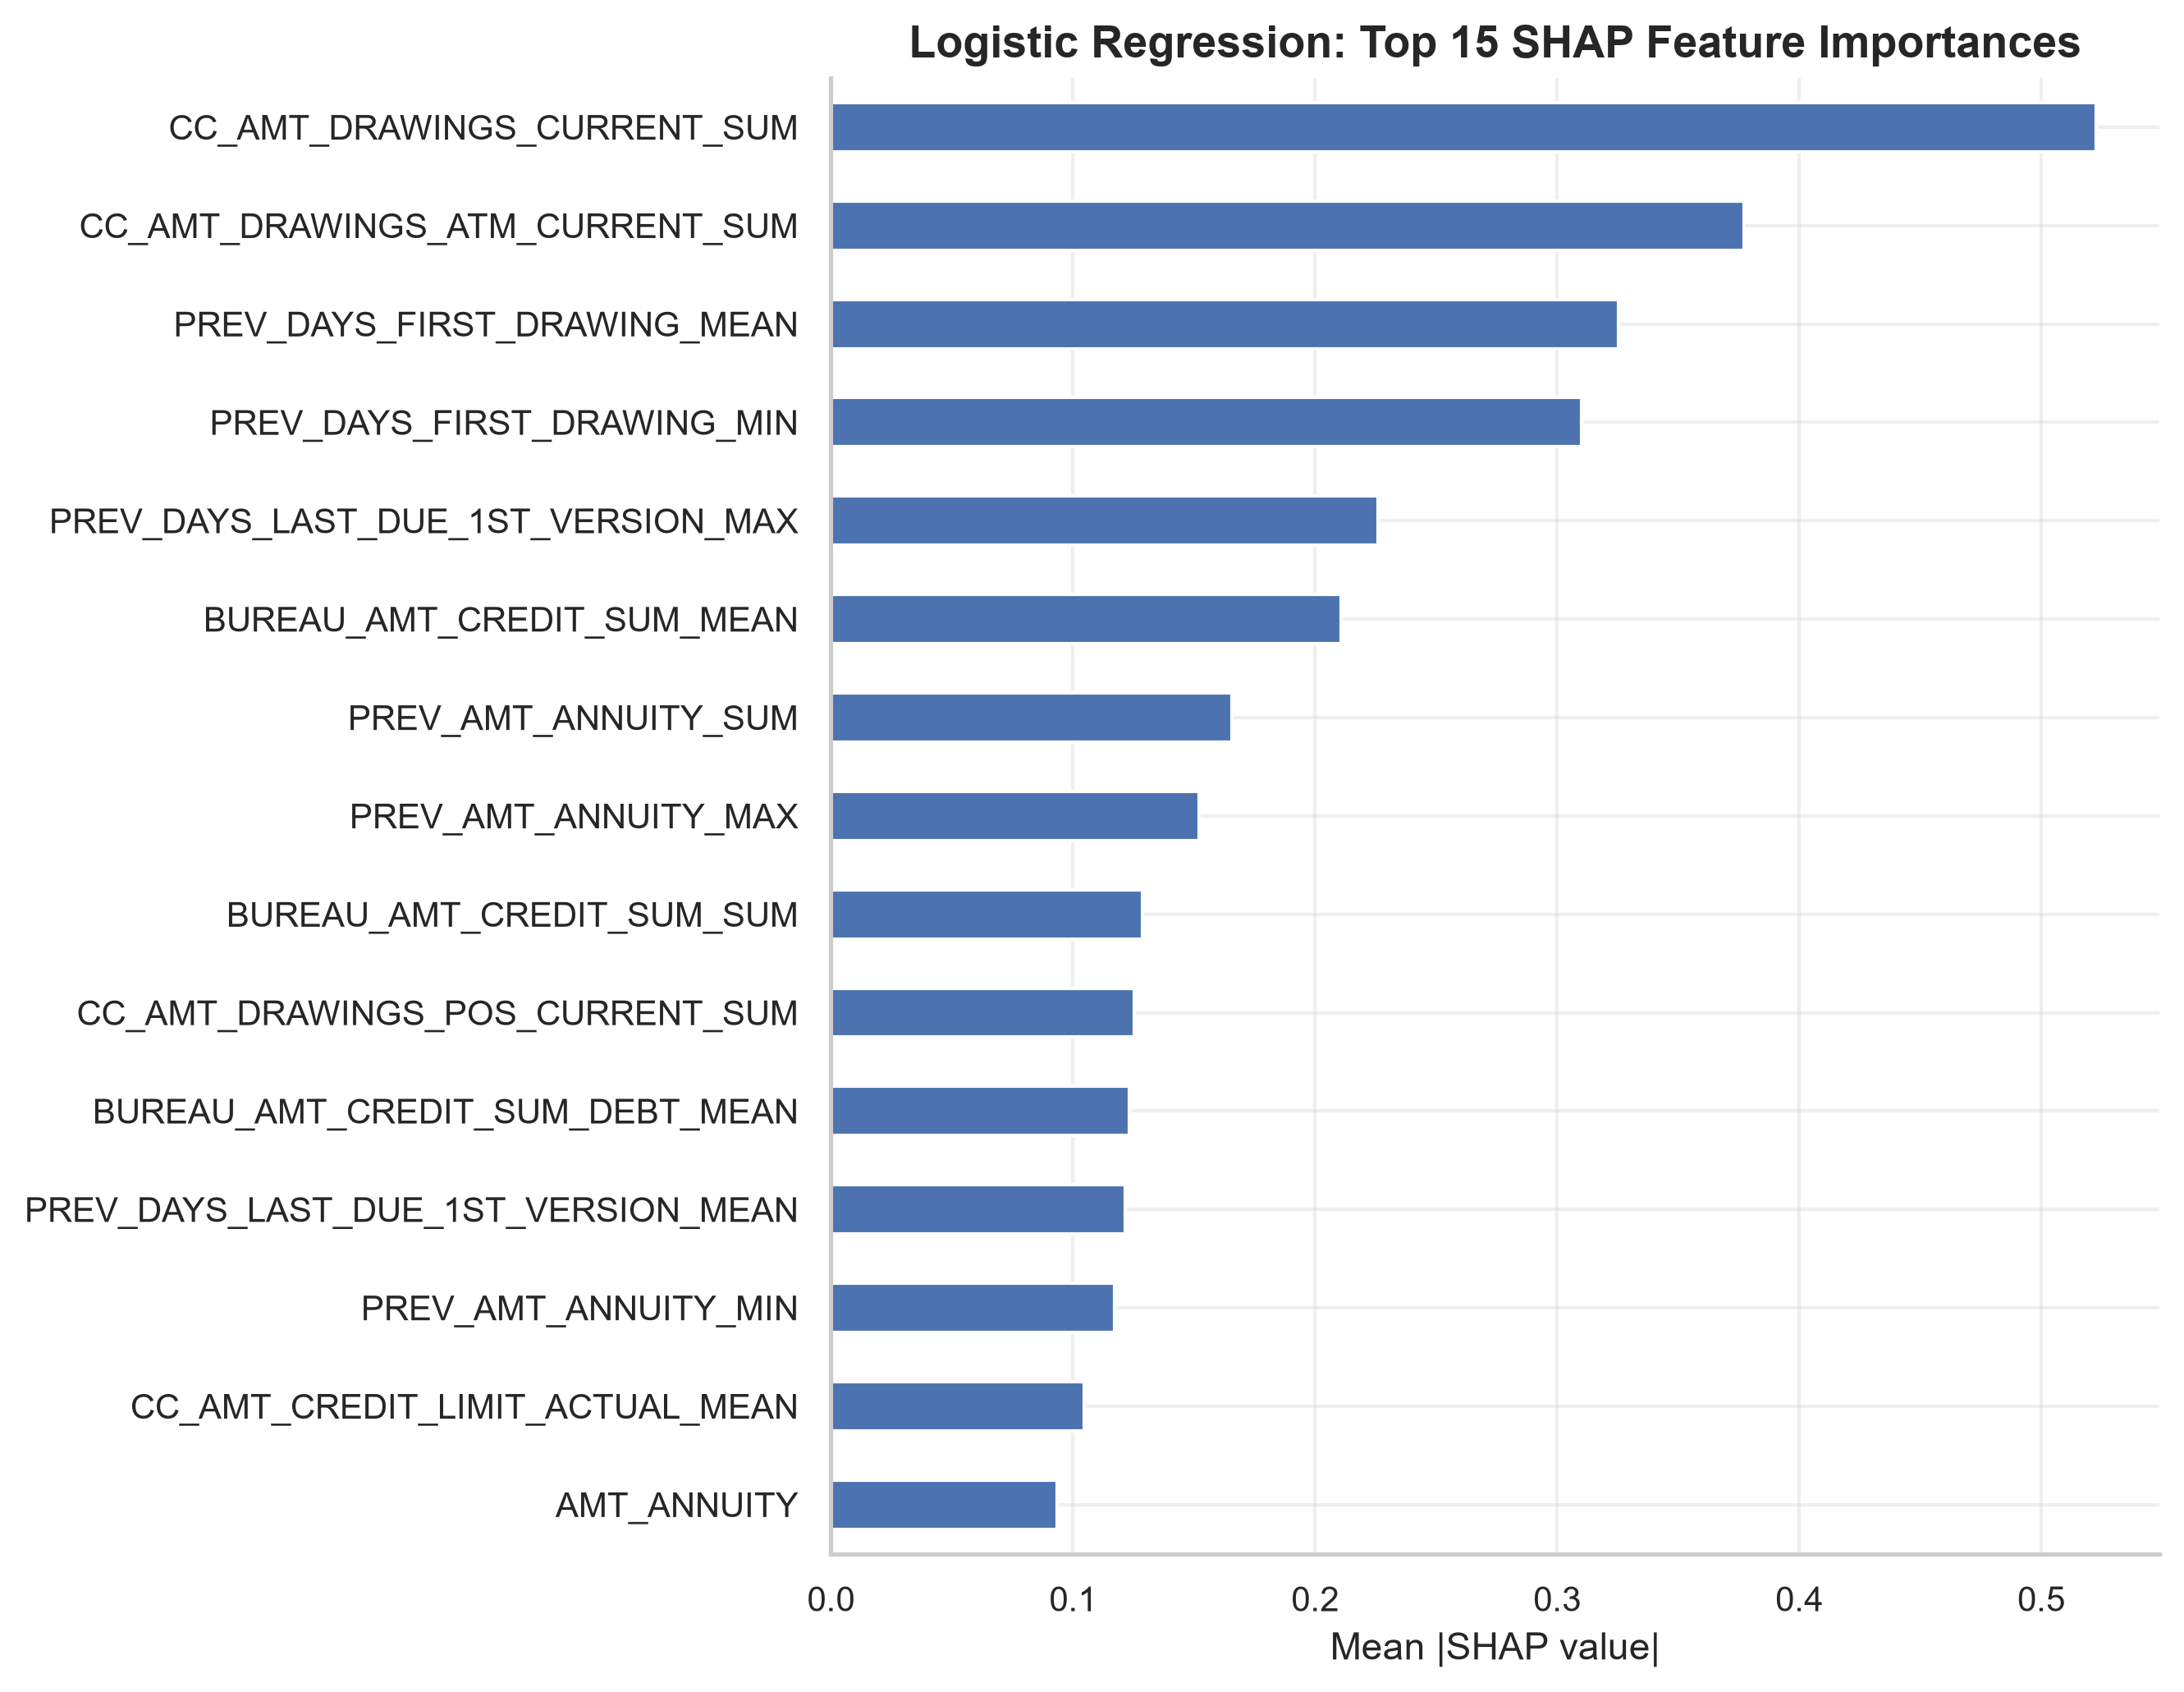

Figure saved to: ..\figures\06_logreg_shap_dependence.png


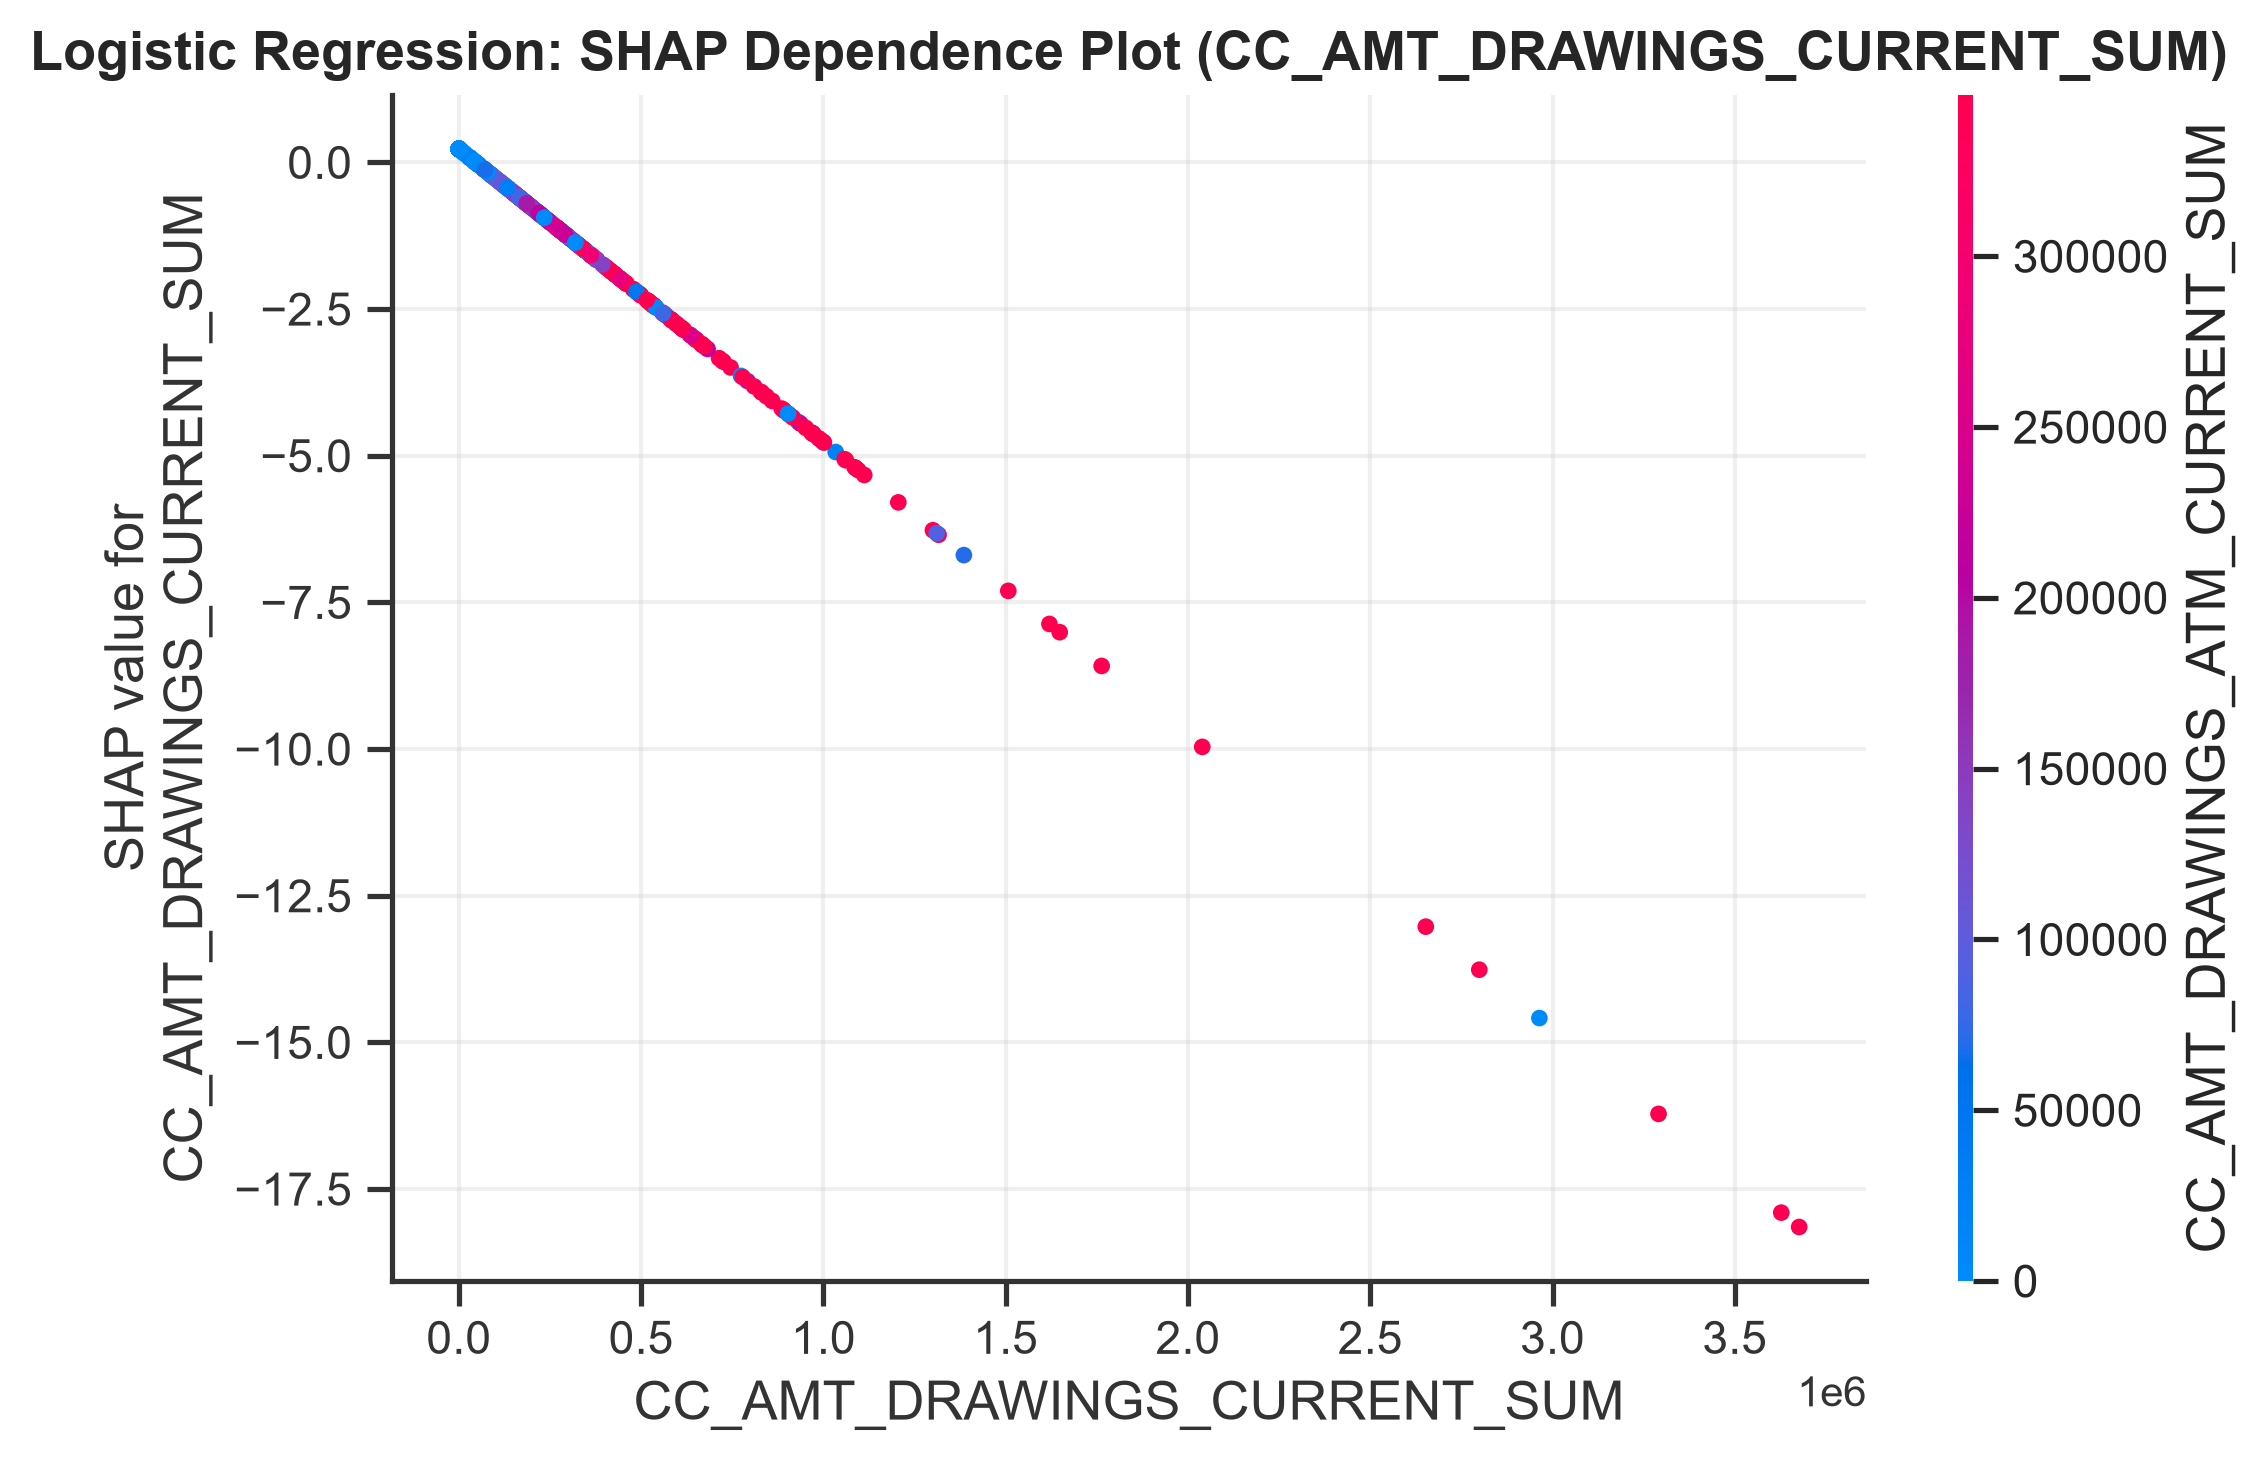

,Mean |SHAP value|
CC_AMT_DRAWINGS_CURRENT_SUM,0.522665
CC_AMT_DRAWINGS_ATM_CURRENT_SUM,0.377273
PREV_DAYS_FIRST_DRAWING_MEAN,0.325400
PREV_DAYS_FIRST_DRAWING_MIN,0.310245
PREV_DAYS_LAST_DUE_1ST_VERSION_MAX,0.225882
BUREAU_AMT_CREDIT_SUM_MEAN,0.210842
PREV_AMT_ANNUITY_SUM,0.165481
PREV_AMT_ANNUITY_MAX,0.151985
BUREAU_AMT_CREDIT_SUM_SUM,0.128621
CC_AMT_DRAWINGS_POS_CURRENT_SUM,0.125255


In [20]:
# ============================================================
# SHAP Feature Importance & Dependence Plot
# ============================================================

# --- Global Feature Importance (mean absolute SHAP value) ---
mean_abs_shap = pd.Series(
    np.abs(shap_values.values).mean(axis=0), index=X_test_full.columns
).sort_values(ascending=False)

top_features = mean_abs_shap.head(15)

fig, ax = plt.subplots(figsize=(9, 7))
top_features.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("Logistic Regression: Top 15 SHAP Feature Importances")
plt.tight_layout()
pu.save_fig(fig, "06_logreg_shap_feature_importance")
plt.show()

top_features_table = top_features.to_frame("Mean |SHAP value|")
top_features_table.to_csv(Path("../results") / "06_logreg_shap_top_features.csv")

# --- Dependence Plot for the single most important feature ---
top_feature_name = mean_abs_shap.index[0]

shap.dependence_plot(
    top_feature_name, shap_values.values, shap_sample, show=False
)
fig = plt.gcf()
plt.title(f"Logistic Regression: SHAP Dependence Plot ({top_feature_name})")
plt.tight_layout()
pu.save_fig(fig, "06_logreg_shap_dependence")
plt.show()

top_features_table

Low-risk applicant  - predicted default probability: 0.0008
High-risk applicant - predicted default probability: 0.9639


Figure saved to: ..\figures\06_logreg_shap_local_low_risk.png


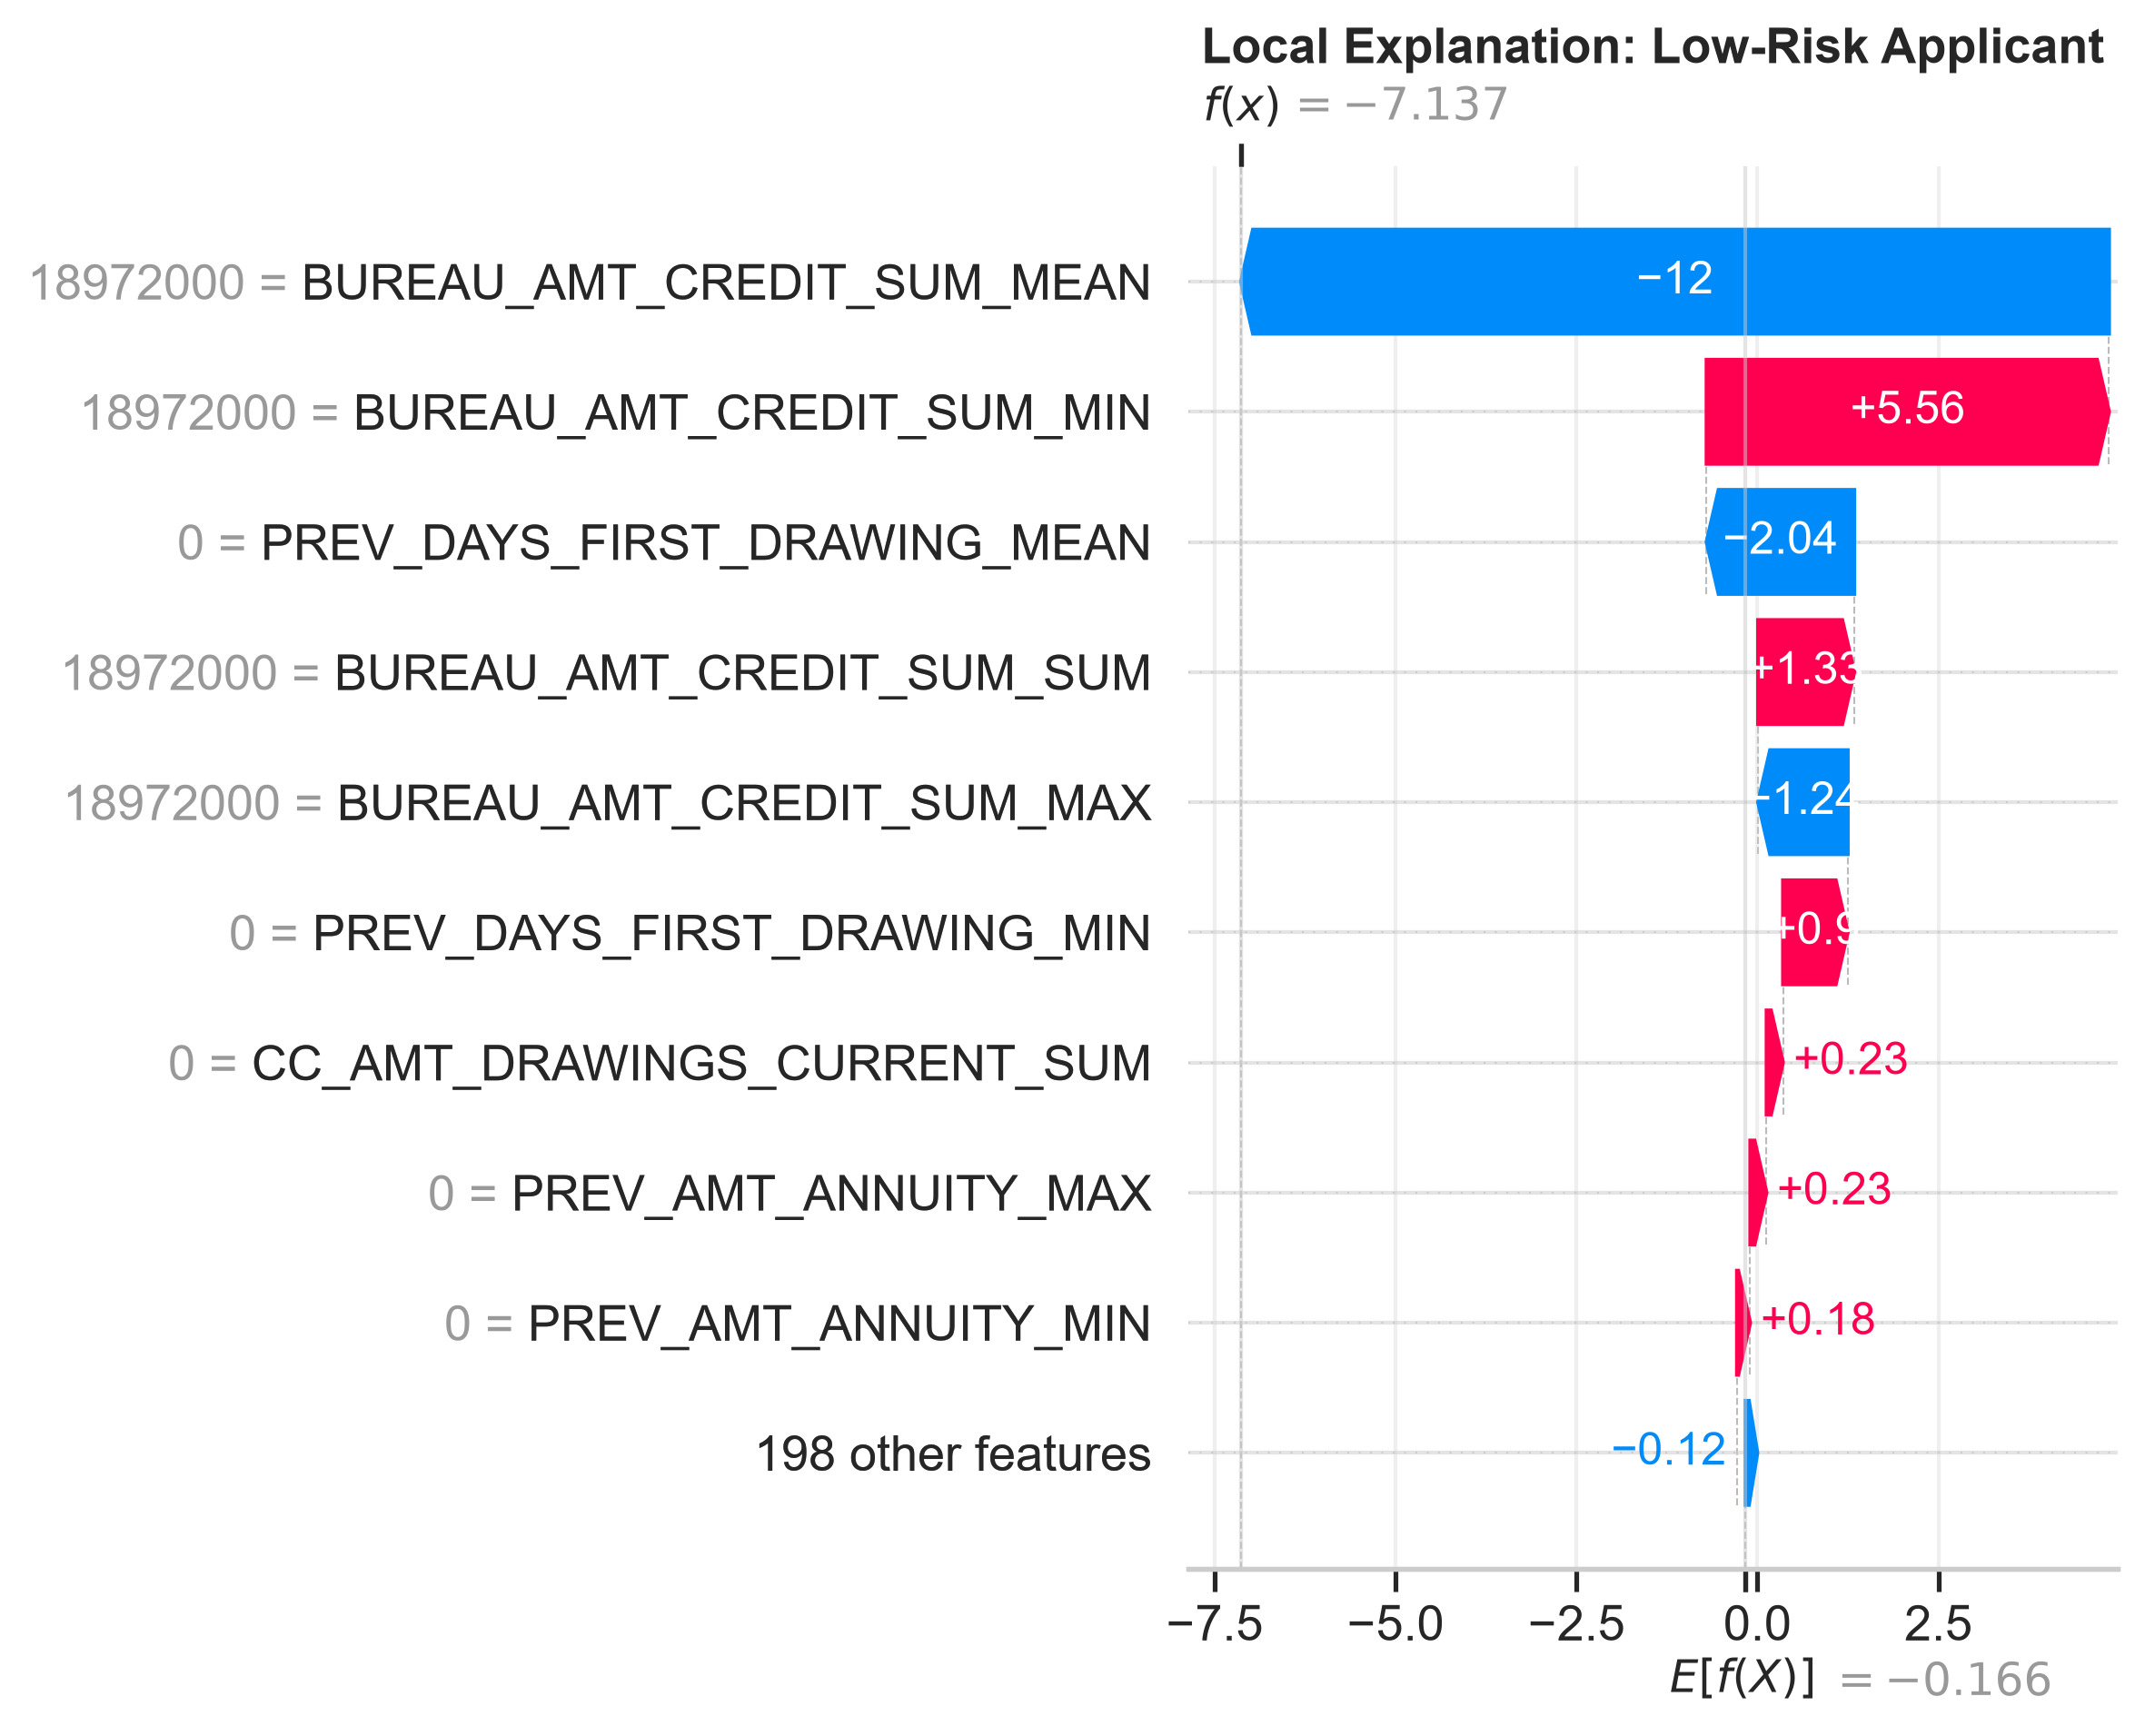

Figure saved to: ..\figures\06_logreg_shap_local_high_risk.png


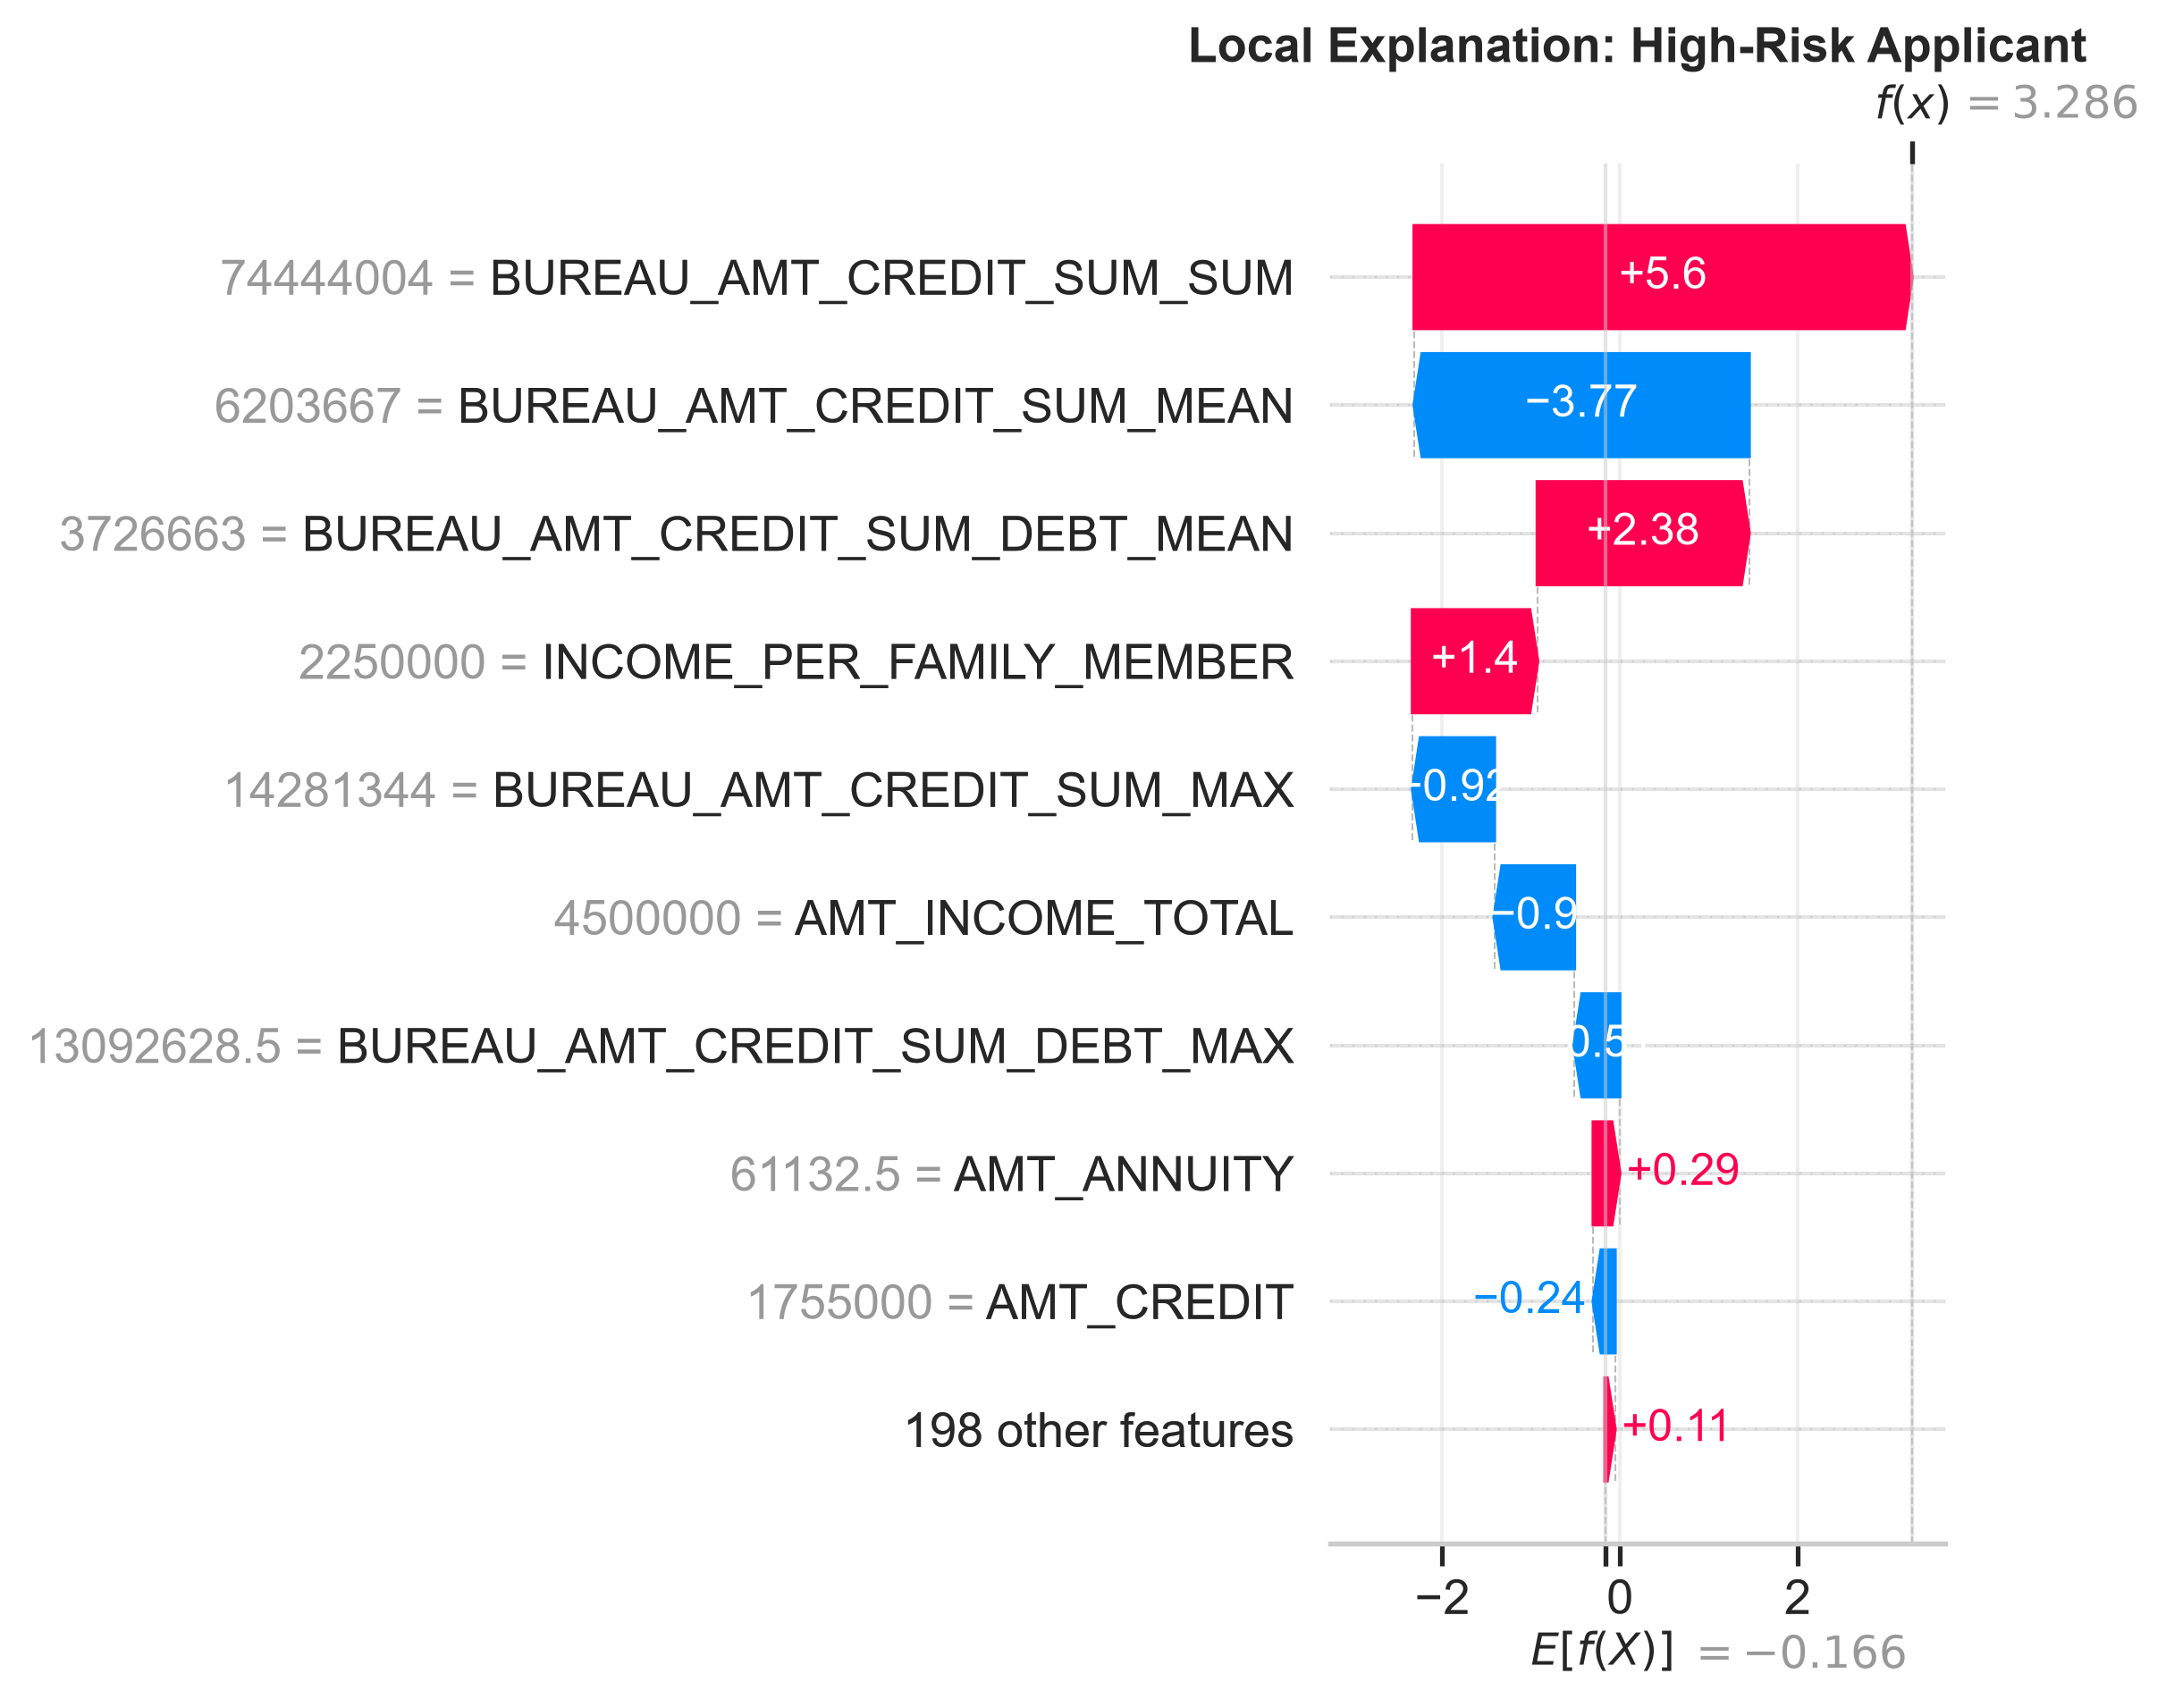

In [21]:
# ============================================================
# Local SHAP Explanations: One Low-Risk and One High-Risk Applicant
# ============================================================

predicted_prob_shap_sample = logistic_model_shap.predict_proba(shap_sample)[:, 1]

low_risk_idx = int(np.argmin(predicted_prob_shap_sample))
high_risk_idx = int(np.argmax(predicted_prob_shap_sample))

print(f"Low-risk applicant  - predicted default probability: {predicted_prob_shap_sample[low_risk_idx]:.4f}")
print(f"High-risk applicant - predicted default probability: {predicted_prob_shap_sample[high_risk_idx]:.4f}")

fig = plt.figure(figsize=(9, 6))
shap.plots.waterfall(shap_values[low_risk_idx], show=False)
plt.title("Local Explanation: Low-Risk Applicant")
plt.tight_layout()
pu.save_fig(fig, "06_logreg_shap_local_low_risk")
plt.show()

fig = plt.figure(figsize=(9, 6))
shap.plots.waterfall(shap_values[high_risk_idx], show=False)
plt.title("Local Explanation: High-Risk Applicant")
plt.tight_layout()
pu.save_fig(fig, "06_logreg_shap_local_high_risk")
plt.show()

### Business Interpretation: SHAP Explainability

The summary plot ranks features by their overall impact on predicted default risk and
shows the *direction* of that impact (e.g., low `EXT_SOURCE_MEAN` — a low external
credit-bureau score — pushing predictions toward higher default risk, shown in a
distinct color at the high-SHAP-value end). This directly supports **adverse action
reporting**: under ECOA (US) and GDPR Article 22 (EU), a lender that declines an
applicant using an automated model must be able to state the principal reasons for the
decision, and the top features from the SHAP summary plot are exactly the candidates
for those stated reasons. The dependence plot for the top feature typically reveals
whether the relationship is linear (consistent with Logistic Regression's functional
form) or shows interaction effects with a secondary coloring feature, which is useful
evidence when deciding whether a linear model is mis-specified relative to the
tree-based alternatives.

The two local (waterfall) explanations translate the model from "a population-level
scorecard" into "an individually justifiable decision": the high-risk applicant's
waterfall plot shows which specific attributes (e.g., high `CREDIT_INCOME_RATIO`, short
employment tenure) pushed their predicted probability up from the population average,
while the low-risk applicant's plot shows the opposite. These per-applicant
explanations are what a loan officer would actually show a customer or a regulator on
request, and are saved to `figures/` for direct inclusion in the paper's Discussion or
Appendix as a worked example.